In [ ]:
# detect the Ubuntu codename Colab is running (usually 'jammy' = 22.04)
codename <- system("lsb_release -cs", intern = TRUE)
cat("Ubuntu codename:", codename, "\n")

# point R at Posit's PRE-COMPILED binaries instead of source (this is the whole fix)
options(repos = c(CRAN = paste0(
  "https://packagemanager.posit.co/cran/__linux__/", codename, "/latest")))
options(HTTPUserAgent = sprintf(
  "R/%s R (%s)", getRversion(),
  paste(getRversion(), R.version$platform, R.version$arch, R.version$os)))

# now install — as binaries, in parallel
install.packages(c("xgboost", "factoextra", "reshape2","vcd", "googledrive","visdat","lubridate","skimr", "corrplot", "lightgbm", "pROC","e1071", "glmnet","janitor", "dplyr","smotefamily"), Ncpus = 4)

Ubuntu codename: jammy 


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘fracdiff’, ‘timeDate’, ‘urca’, ‘RcppArmadillo’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘litedown’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘lazyeval’, ‘markdown’, ‘png’, ‘jpeg’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’, ‘crosstalk’, ‘estimability’, ‘mvtnorm’, ‘numDeriv’, ‘gridtext’, ‘showtextdb’, ‘viridis’, ‘car’, ‘DT’, ‘ellipse’, ‘emmeans’, ‘flashClust’, ‘ggtext’, ‘irlba’, ‘leaps’, ‘multcompView’, ‘scatterplot3d’, ‘showtext’, ‘sysfonts’, ‘ggsci’, ‘cowplot’, ‘ggsignif’, ‘gridExtra’, ‘polynom’, ‘rstatix’, ‘zoo’, ‘iterators’, ‘dendextend’, ‘FactoMineR’, ‘ggpubr’, ‘ggrepel’, ‘plyr’, ‘colorspace’, ‘lmtest’, ‘proxy’, ‘foreach’, ‘shape’, ‘RcppEigen’, ‘snakecase’, ‘FNN’, ‘dbscan’, ‘igraph’




INSTALL PACKAGES

In [ ]:
library(tidyverse)
library(lubridate)
library(janitor)
library(skimr)
library(visdat)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘janitor’


The following objects are masked from ‘package:stats’:

    chisq.test, fisher.test




Load Dataset

In [ ]:
install.packages("googledrive")
library(googledrive)


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
system("pip install -q gdown")
system('gdown --fuzzy "https://drive.google.com/file/d/1oVJFbcZnTnCKykBsq0C4EwtvKlHVgQVW/view?usp=drive_link" -O /content/loan.csv')

In [ ]:
loan_data <- read.csv(
  "/content/loan.csv",
  na.strings = c("", "NA", "n/a")
)

dim(loan_data)
head(loan_data)

[1] 39717   111

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,⋯,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit
,<int>,<int>,<int>,<int>,<dbl>,<chr>,<chr>,<dbl>,<chr>,<chr>,⋯,<lgl>,<lgl>,<lgl>,<lgl>,<int>,<int>,<lgl>,<lgl>,<lgl>,<lgl>
1,1077501,1296599,5000,5000,4975,36 months,10.65%,162.87,B,B2,⋯,NA,NA,NA,NA,0,0,NA,NA,NA,NA
2,1077430,1314167,2500,2500,2500,60 months,15.27%,59.83,C,C4,⋯,NA,NA,NA,NA,0,0,NA,NA,NA,NA
3,1077175,1313524,2400,2400,2400,36 months,15.96%,84.33,C,C5,⋯,NA,NA,NA,NA,0,0,NA,NA,NA,NA
4,1076863,1277178,10000,10000,10000,36 months,13.49%,339.31,C,C1,⋯,NA,NA,NA,NA,0,0,NA,NA,NA,NA
5,1075358,1311748,3000,3000,3000,60 months,12.69%,67.79,B,B5,⋯,NA,NA,NA,NA,0,0,NA,NA,NA,NA
6,1075269,1311441,5000,5000,5000,36 months,7.90%,156.46,A,A4,⋯,NA,NA,NA,NA,0,0,NA,NA,NA,NA


CHECK FOR MISSING VALUES

In [ ]:
missing_summary<-data.frame(
  Column = names(loan_data),
  Missing = colSums(is.na(loan_data)),
  Pct = round(colSums(is.na(loan_data))/nrow(loan_data) * 100, 2)
)%>%
   filter(Missing > 0) %>%
   arrange(desc(Pct))
print(missing_summary)

                                                       Column Missing    Pct
mths_since_last_major_derog       mths_since_last_major_derog   39717 100.00
annual_inc_joint                             annual_inc_joint   39717 100.00
dti_joint                                           dti_joint   39717 100.00
verification_status_joint           verification_status_joint   39717 100.00
tot_coll_amt                                     tot_coll_amt   39717 100.00
tot_cur_bal                                       tot_cur_bal   39717 100.00
open_acc_6m                                       open_acc_6m   39717 100.00
open_il_6m                                         open_il_6m   39717 100.00
open_il_12m                                       open_il_12m   39717 100.00
open_il_24m                                       open_il_24m   39717 100.00
mths_since_rcnt_il                         mths_since_rcnt_il   39717 100.00
total_bal_il                                     total_bal_il   39717 100.00

DROP COLUMNS WITH 100% MISSING VALUES

In [ ]:
cols_100_missing<-missing_summary %>%
  filter(Pct==100) %>%
  pull(Column)
loan_data<-loan_data %>%
  select(-all_of(cols_100_missing))
dim(loan_data)

[1] 39717    57

RECHECK MISSINGNESS

In [ ]:
missing_summary2 <- data.frame(
  Column = names(loan_data),
  Missing = colSums(is.na(loan_data)),
  Pct = round(colSums(is.na(loan_data))/nrow(loan_data) * 100, 2)
) %>%
  filter(Missing > 0) %>%
  arrange(desc(Pct))

print(missing_summary2)

                                               Column Missing   Pct
next_pymnt_d                             next_pymnt_d   38577 97.13
mths_since_last_record         mths_since_last_record   36931 92.99
mths_since_last_delinq         mths_since_last_delinq   25682 64.66
desc                                             desc   12940 32.58
emp_title                                   emp_title    2454  6.18
emp_length                                 emp_length    1075  2.71
pub_rec_bankruptcies             pub_rec_bankruptcies     697  1.75
last_pymnt_d                             last_pymnt_d      71  0.18
collections_12_mths_ex_med collections_12_mths_ex_med      56  0.14
chargeoff_within_12_mths     chargeoff_within_12_mths      56  0.14
revol_util                                 revol_util      50  0.13
tax_liens                                   tax_liens      39  0.10
title                                           title      11  0.03
last_credit_pull_d                 last_credit_p

desc is description which has unstructured free text with thousands of unique values. We have a better structured column: Purpose

In [ ]:
loan_data <- loan_data %>% select(-desc)

dim(loan_data)
colSums(is.na(loan_data))


[1] 39717    56

id                  member_id 
                         0                          0 
                 loan_amnt                funded_amnt 
                         0                          0 
           funded_amnt_inv                       term 
                         0                          0 
                  int_rate                installment 
                         0                          0 
                     grade                  sub_grade 
                         0                          0 
                 emp_title                 emp_length 
                      2454                       1075 
            home_ownership                 annual_inc 
                         0                          0 
       verification_status                    issue_d 
                         0                          0 
               loan_status                 pymnt_plan 
                         0                          0 
                       url                    purpose 
                         0                          0 
                     title                   zip_code 
                        11                          0 
                addr_state                        dti 
                         0                          0 
               delinq_2yrs           earliest_cr_line 
                         0                          0 
            inq_last_6mths     mths_since_last_delinq 
                         0                      25682 
    mths_since_last_record                   open_acc 
                     36931                          0 
                   pub_rec                  revol_bal 
                         0                          0 
                revol_util                  total_acc 
                        50                          0 
       initial_list_status                  out_prncp 
                         0                          0 
             out_prncp_inv                total_pymnt 
                         0                          0 
           total_pymnt_inv            total_rec_prncp 
                         0                          0 
             total_rec_int         total_rec_late_fee 
                         0                          0 
                recoveries    collection_recovery_fee 
                         0                          0 
              last_pymnt_d            last_pymnt_amnt 
                        71                          0 
              next_pymnt_d         last_credit_pull_d 
                     38577                          2 
collections_12_mths_ex_med                policy_code 
                        56                          0 
          application_type             acc_now_delinq 
                         0                          0 
  chargeoff_within_12_mths                delinq_amnt 
                        56                          0 
      pub_rec_bankruptcies                  tax_liens 
                       697                         39

pymnt_plan has value "n" for all rows and url is just a link to the loan page and has no analytical value

In [ ]:
loan_data <- loan_data %>% select(-pymnt_plan, -url)

dim(loan_data)

[1] 39717    54

In [ ]:
install.packages("openxlsx")
library(openxlsx)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



CHECKING THE NUMBER OF UNIQUE VALUES IN EACH COLUMN

In [ ]:
unique_summary <- data.frame(
  Column = names(loan_data),
  Unique_Values = sapply(loan_data, function(x) length(unique(x)))
)

print(unique_summary)

                                               Column Unique_Values
id                                                 id         39717
member_id                                   member_id         39717
loan_amnt                                   loan_amnt           885
funded_amnt                               funded_amnt          1041
funded_amnt_inv                       funded_amnt_inv          8205
term                                             term             2
int_rate                                     int_rate           371
installment                               installment         15383
grade                                           grade             7
sub_grade                                   sub_grade            35
emp_title                                   emp_title         28822
emp_length                                 emp_length            12
home_ownership                         home_ownership             5
annual_inc                                 annua

WE SEE SOME COLUMNS HAVE ONLY 1 UNIQUE VALUES. TO FIND THESE COLUMNS

In [ ]:
constant_cols <- names(loan_data)[sapply(loan_data, function(x) length(unique(x)) == 1)]
constant_cols

[1] "initial_list_status" "policy_code"         "application_type"   
[4] "acc_now_delinq"      "delinq_amnt"

REMOVE THOSE COLUMNS

In [ ]:
loan_data <- loan_data %>%
  select(-initial_list_status,
         -policy_code,
         -application_type,
         -acc_now_delinq,
         -delinq_amnt)

In [ ]:
dim(loan_data)
names(loan_data)

[1] 39717    49

[1] "id"                         "member_id"                 
 [3] "loan_amnt"                  "funded_amnt"               
 [5] "funded_amnt_inv"            "term"                      
 [7] "int_rate"                   "installment"               
 [9] "grade"                      "sub_grade"                 
[11] "emp_title"                  "emp_length"                
[13] "home_ownership"             "annual_inc"                
[15] "verification_status"        "issue_d"                   
[17] "loan_status"                "purpose"                   
[19] "title"                      "zip_code"                  
[21] "addr_state"                 "dti"                       
[23] "delinq_2yrs"                "earliest_cr_line"          
[25] "inq_last_6mths"             "mths_since_last_delinq"    
[27] "mths_since_last_record"     "open_acc"                  
[29] "pub_rec"                    "revol_bal"                 
[31] "revol_util"                 "total_acc"                 
[33] "out_prncp"                  "out_prncp_inv"             
[35] "total_pymnt"                "total_pymnt_inv"           
[37] "total_rec_prncp"            "total_rec_int"             
[39] "total_rec_late_fee"         "recoveries"                
[41] "collection_recovery_fee"    "last_pymnt_d"              
[43] "last_pymnt_amnt"            "next_pymnt_d"              
[45] "last_credit_pull_d"         "collections_12_mths_ex_med"
[47] "chargeoff_within_12_mths"   "pub_rec_bankruptcies"      
[49] "tax_liens"

CHECKING UNIQUE VALUES FOR A LIST OF COLUMNS

In [ ]:
library(knitr)
cols <- c(
  "verification_status",
  "home_ownership",
  "purpose",
  "pub_rec",
  "pub_rec_bankruptcies",
  "tax_liens",
  "chargeoff_within_12_mths"
)

for (col in cols) {
  cat("\n\n###", col, "\n")
  print(kable(as.data.frame(table(loan_data[[col]])),
              col.names = c("Value", "Count")))
}



### verification_status 


|Value           | Count|
|:---------------|-----:|
|Not Verified    | 16921|
|Source Verified |  9987|
|Verified        | 12809|


### home_ownership 


|Value    | Count|
|:--------|-----:|
|MORTGAGE | 17659|
|NONE     |     3|
|OTHER    |    98|
|OWN      |  3058|
|RENT     | 18899|


### purpose 


|Value              | Count|
|:------------------|-----:|
|car                |  1549|
|credit_card        |  5130|
|debt_consolidation | 18641|
|educational        |   325|
|home_improvement   |  2976|
|house              |   381|
|major_purchase     |  2187|
|medical            |   693|
|moving             |   583|
|other              |  3993|
|renewable_energy   |   103|
|small_business     |  1828|
|vacation           |   381|
|wedding            |   947|


### pub_rec 


|Value | Count|
|:-----|-----:|
|0     | 37601|
|1     |  2056|
|2     |    51|
|3     |     7|
|4     |     2|


### pub_rec_bankruptcies 


|Value | Count|
|:-----|-----:|
|0     | 373

Among the unique values, tax_liens and chargeoff_within_12_mths have either missing or 0 values. In these, even if we impute with 0, the column becomes 100% 0. So it is better to drop these columns

In [ ]:
loan_data <- loan_data %>%
  select(-tax_liens,
         -chargeoff_within_12_mths)

In [ ]:
dim(loan_data)


[1] 39717    47

Checking if in pub_rec and pub_rec_bankrupties, numbers provide meaning or not

In [ ]:
pub_rec_analysis <- loan_data %>%
  filter(pub_rec >= 2) %>%
  count(pub_rec, loan_status)

pub_rec_analysis

bankruptcy_analysis <- loan_data %>%
  count(pub_rec_bankruptcies, loan_status)

bankruptcy_analysis

pub_rec,loan_status,n
<int>,<chr>,<int>
2,Charged Off,10
2,Current,3
2,Fully Paid,38
3,Fully Paid,7
4,Fully Paid,2


pub_rec_bankruptcies,loan_status,n
<int>,<chr>,<int>
0,Charged Off,5141
0,Current,1101
0,Fully Paid,31097
1,Charged Off,366
1,Current,37
1,Fully Paid,1271
2,Charged Off,2
2,Current,2
2,Fully Paid,3


Adding binary flags for these columns as missing value rarely means they did not record bankrupties. Missing value usually means they don't have record of bankrupties.

In [ ]:
library(dplyr)

loan_data <- loan_data %>%
  mutate(
    # 0 = no record, 1 = one or more records
    pub_rec_binary = ifelse(is.na(pub_rec), NA,
                            ifelse(pub_rec > 0, 1, 0)),

    pub_rec_bankruptcies_binary = ifelse(is.na(pub_rec_bankruptcies), NA,
                                         ifelse(pub_rec_bankruptcies > 0, 1, 0))
  ) %>%
  select(-pub_rec, -pub_rec_bankruptcies)

In [ ]:
install.packages("psych")
library(psych)

describe(loan_data)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘mnormt’, ‘GPArotation’



Attaching package: ‘psych’


The following objects are masked from ‘package:ggplot2’:

    %+%, alpha




,vars,n,mean,sd,median,trimmed,mad,min,max,range,skew,kurtosis,se
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
id,1,39717,6.831319e+05,2.106941e+05,665665.00,6.806747e+05,2.372545e+05,54734.00,1077501.00,1022767.00,0.078801679,-0.73006289,1.057217e+03
member_id,2,39717,8.504636e+05,2.656783e+05,850812.00,8.583849e+05,2.823271e+05,70699.00,1314167.00,1243468.00,-0.212400327,-0.56317092,1.333116e+03
loan_amnt,3,39717,1.121944e+04,7.456671e+03,10000.00,1.031914e+04,7.413000e+03,500.00,35000.00,34500.00,1.059237276,0.76823096,3.741595e+01
funded_amnt,4,39717,1.094771e+04,7.187239e+03,9600.00,1.009085e+04,6.819960e+03,500.00,35000.00,34500.00,1.081628533,0.93708464,3.606400e+01
funded_amnt_inv,5,39717,1.039745e+04,7.128450e+03,8975.00,9.549683e+03,6.226920e+03,0.00,35000.00,35000.00,1.106129383,1.06205498,3.576901e+01
term*,6,39717,1.267417e+00,4.426173e-01,1.00,1.209284e+00,0.000000e+00,1.00,2.00,1.00,1.050917675,-0.89559459,2.220957e-03
int_rate*,7,39717,1.797293e+02,1.220298e+02,160.00,1.780411e+02,1.675338e+02,1.00,371.00,370.00,0.173125256,-1.48112148,6.123191e-01
installment,8,39717,3.245619e+02,2.088749e+02,280.22,2.993748e+02,1.826563e+02,15.69,1305.19,1289.50,1.128333862,1.24627945,1.048089e+00
grade*,9,39717,2.577309e+00,1.387286e+00,2.00,2.418757e+00,1.482600e+00,1.00,7.00,6.00,0.790407352,0.04895179,6.961096e-03


home_ownership has "none" values. they can be considered as "other"

In [ ]:
library(dplyr)

loan_data <- loan_data %>%
  mutate(
    home_ownership = ifelse(home_ownership == "NONE",
                            "OTHER",
                            home_ownership)
  )
table(loan_data$home_ownership)


MORTGAGE    OTHER      OWN     RENT 
   17659      101     3058    18899 

Title can be removed because it is a text field with 19,616 unique values. It is redundant with "purpose" tjat captures the loan purpose in 14 categories. Additionally, keeping it would increase dimensionality without adding additional information for modelling.

In [ ]:
loan_data <- loan_data %>%
  select(-title)

In [ ]:
names(loan_data)

[1] "id"                          "member_id"                  
 [3] "loan_amnt"                   "funded_amnt"                
 [5] "funded_amnt_inv"             "term"                       
 [7] "int_rate"                    "installment"                
 [9] "grade"                       "sub_grade"                  
[11] "emp_title"                   "emp_length"                 
[13] "home_ownership"              "annual_inc"                 
[15] "verification_status"         "issue_d"                    
[17] "loan_status"                 "purpose"                    
[19] "zip_code"                    "addr_state"                 
[21] "dti"                         "delinq_2yrs"                
[23] "earliest_cr_line"            "inq_last_6mths"             
[25] "mths_since_last_delinq"      "mths_since_last_record"     
[27] "open_acc"                    "revol_bal"                  
[29] "revol_util"                  "total_acc"                  
[31] "out_prncp"                   "out_prncp_inv"              
[33] "total_pymnt"                 "total_pymnt_inv"            
[35] "total_rec_prncp"             "total_rec_int"              
[37] "total_rec_late_fee"          "recoveries"                 
[39] "collection_recovery_fee"     "last_pymnt_d"               
[41] "last_pymnt_amnt"             "next_pymnt_d"               
[43] "last_credit_pull_d"          "collections_12_mths_ex_med" 
[45] "pub_rec_binary"              "pub_rec_bankruptcies_binary"

In [ ]:
table(loan_data$loan_status, is.na(loan_data$next_pymnt_d))

             
              FALSE  TRUE
  Charged Off     0  5627
  Current      1140     0
  Fully Paid      0 32950

Leakage column removal

In [ ]:
loan_data <- loan_data %>%
  select(-next_pymnt_d)

In [ ]:
emp_title_unique <- data.frame(
  emp_title = unique(loan_data$emp_title)
)

View(emp_title_unique)

emp_title
<chr>
NA
Ryder
AIR RESOURCES BOARD
University Medical Group
Veolia Transportaton
Southern Star Photography
MKC Accounting
Starbucks
Southwest Rural metro


In [ ]:
# Remove emp_title because it is a high-cardinality free-text employment field
# with 28,822 unique values. Most categories occur rarely, creating sparse
# representations during encoding. Employment-related information is partially
# captured by other variables such as emp_length and annual_inc.
loan_data <- loan_data %>%
  select(-emp_title)

In [ ]:
loan_data %>%
  count(mths_since_last_delinq, sort = TRUE)

mths_since_last_delinq,n
<int>,<int>
NA,25682
0,443
15,252
23,247
30,247
24,241
19,238
38,237
20,233


In [ ]:
loan_data %>%
  count(delinq_2yrs, is.na(mths_since_last_delinq))

delinq_2yrs,is.na(mths_since_last_delinq),n
<int>,<lgl>,<int>
0,FALSE,9723
0,TRUE,25682
1,FALSE,3303
2,FALSE,687
3,FALSE,220
4,FALSE,62
5,FALSE,22
6,FALSE,10
7,FALSE,4


In [ ]:
# mths_since_last_delinq: NA does NOT mean missing/bad data.
# We confirmed earlier that every NA here corresponds to delinq_2yrs = 0,
# meaning these borrowers have NEVER had a delinquency - so there's no
# "months since" value to record. This is structural missingness, not a data gap.
loan_data <- loan_data %>%
  mutate(
    never_delinq = ifelse(is.na(mths_since_last_delinq), 1, 0),
    mths_since_last_delinq = ifelse(is.na(mths_since_last_delinq), 999, mths_since_last_delinq)
  )

# check
sum(is.na(loan_data$mths_since_last_delinq))   # should be 0
loan_data %>% count(never_delinq)

[1] 0

never_delinq,n
<dbl>,<int>
0,14035
1,25682


In [ ]:
# STEP 1: Find the mode FIRST
mode_date <- names(sort(table(loan_data$last_credit_pull_d), decreasing = TRUE))[1]

# STEP 2: Fill the NAs with mode
loan_data <- loan_data %>%
  mutate(last_credit_pull_d = ifelse(is.na(last_credit_pull_d), mode_date, last_credit_pull_d))

# STEP 3: NOW check that NAs are gone
sum(is.na(loan_data$last_credit_pull_d))  # Should be 0

# STEP 4: See what the mode date is
print(paste("Mode date:", mode_date))

# STEP 5: Check distribution
table(loan_data$last_credit_pull_d) %>% sort(decreasing = TRUE) %>% head(10)

[1] 0

[1] "Mode date: May-16"



May-16 Apr-16 Mar-16 Feb-13 Feb-16 Jan-16 Dec-15 Mar-13 Mar-14 Dec-14 
 10310   2547   1123    843    736    657    647    577    564    562 

In [ ]:
loan_data <- loan_data %>%
  mutate(last_credit_pull_d = my(last_credit_pull_d))

class(loan_data$last_credit_pull_d)
head(loan_data$last_credit_pull_d)
sum(is.na(loan_data$last_credit_pull_d))

[1] "Date"

[1] "2016-05-01" "2013-09-01" "2016-05-01" "2016-04-01" "2016-05-01"
[6] "2016-01-01"

[1] 0

In [ ]:
table(loan_data$emp_length, useNA = "ifany")


 < 1 year    1 year 10+ years   2 years   3 years   4 years   5 years   6 years 
     4583      3240      8879      4388      4095      3436      3282      2229 
  7 years   8 years   9 years      <NA> 
     1773      1479      1258      1075 

In [ ]:
#emp_length has become emo_length_years as we tried to fix the data
library(dplyr)

loan_data <- loan_data %>%
  rename(emp_length_years = emp_length) %>%
  mutate(
    emp_length_years = case_when(
      emp_length_years == "< 1 year" ~ 0,
      emp_length_years == "1 year" ~ 1,
      emp_length_years == "2 years" ~ 2,
      emp_length_years == "3 years" ~ 3,
      emp_length_years == "4 years" ~ 4,
      emp_length_years == "5 years" ~ 5,
      emp_length_years == "6 years" ~ 6,
      emp_length_years == "7 years" ~ 7,
      emp_length_years == "8 years" ~ 8,
      emp_length_years == "9 years" ~ 9,
      emp_length_years == "10+ years" ~ 10,
      TRUE ~ NA_real_
    )
  )

Missing emp_length values are imputed using the median because emp_length_years is an ordinal numerical feature. Median is preferred over mean because it is less affected by the large concentration of borrowers with 10+ years of employment.

In [ ]:
loan_data$emp_length_years[is.na(loan_data$emp_length_years)] <-
  median(loan_data$emp_length_years, na.rm = TRUE)

In [ ]:
unique(loan_data$mths_since_last_record)
summary(loan_data$mths_since_last_record)

[1]  NA 113 105  97  33  93  52  85  90  91 114  92 117  87  45  83 118  38
 [19] 101 100 112 110  88  79  77 107 102  98  95 103  96 116 111  89 108  29
 [37] 106 115  53  86  57  63  94 109  99 104  76  61  28  23  75  47  82  21
 [55]  62  44  80  67 119  42  34  66  58  22  56  72  64  50  69  49  74  35
 [73]  12  26  78  54  37  73  11  31  59  32  81  68  55  39  51  70  30  41
 [91]  71  40  43  27  65  46  19  17  25  13  48  36   7  60  14   6  18   0
[109]  20 120 129   5

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
    0.0    22.0    90.0    69.7   104.0   129.0   36931 

checking for missing values

In [ ]:

missing_summary<-data.frame(
  Column = names(loan_data),
  Missing = colSums(is.na(loan_data)),
  Pct = round(colSums(is.na(loan_data))/nrow(loan_data) * 100, 2)
)%>%
   filter(Missing > 0) %>%
   arrange(desc(Pct))
print(missing_summary)

                                                 Column Missing   Pct
mths_since_last_record           mths_since_last_record   36931 92.99
pub_rec_bankruptcies_binary pub_rec_bankruptcies_binary     697  1.75
last_pymnt_d                               last_pymnt_d      71  0.18
collections_12_mths_ex_med   collections_12_mths_ex_med      56  0.14
revol_util                                   revol_util      50  0.13


Create binary feature indicating whether the borrower has a recorded public record. Missing values in mths_since_last_record represent borrowers with no public record history, while non-missing values indicate the presence of a public record

In [ ]:
loan_data <- loan_data %>%
  mutate(
    has_public_record = ifelse(is.na(mths_since_last_record), 0, 1),

    # Replace missing values with 999 instead of using mean/median imputation.
    # Since NA indicates no public record rather than missing random data, 999 preserves this
    # information while keeping the variable numerical. Actual values range from 0-129 months,
    # so 999 acts as a separate indicator for "no public record history".
    mths_since_last_record = ifelse(
      is.na(mths_since_last_record),
      999,
      mths_since_last_record
    )
  )

Inspect the distribution first — bin edges should reflect real breakpoints

In [ ]:
library(dplyr)


loan_data %>%
  filter(!is.na(mths_since_last_record)) %>%
  summarise(
    n    = n(),
    min  = min(mths_since_last_record),
    p25  = quantile(mths_since_last_record, .25),
    med  = median(mths_since_last_record),
    p75  = quantile(mths_since_last_record, .75),
    max  = max(mths_since_last_record)
  )

n,min,p25,med,p75,max
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
39717,0,999,999,999,999


In [ ]:
names(loan_data)

[1] "id"                          "member_id"                  
 [3] "loan_amnt"                   "funded_amnt"                
 [5] "funded_amnt_inv"             "term"                       
 [7] "int_rate"                    "installment"                
 [9] "grade"                       "sub_grade"                  
[11] "emp_length_years"            "home_ownership"             
[13] "annual_inc"                  "verification_status"        
[15] "issue_d"                     "loan_status"                
[17] "purpose"                     "zip_code"                   
[19] "addr_state"                  "dti"                        
[21] "delinq_2yrs"                 "earliest_cr_line"           
[23] "inq_last_6mths"              "mths_since_last_delinq"     
[25] "mths_since_last_record"      "open_acc"                   
[27] "revol_bal"                   "revol_util"                 
[29] "total_acc"                   "out_prncp"                  
[31] "out_prncp_inv"               "total_pymnt"                
[33] "total_pymnt_inv"             "total_rec_prncp"            
[35] "total_rec_int"               "total_rec_late_fee"         
[37] "recoveries"                  "collection_recovery_fee"    
[39] "last_pymnt_d"                "last_pymnt_amnt"            
[41] "last_credit_pull_d"          "collections_12_mths_ex_med" 
[43] "pub_rec_binary"              "pub_rec_bankruptcies_binary"
[45] "never_delinq"                "has_public_record"

In [ ]:
loan_data %>%
  count(last_pymnt_d) %>%
  arrange(last_pymnt_d)

last_pymnt_d,n
<chr>,<int>
Apr-08,12
Apr-09,43
Apr-10,114
Apr-11,420
Apr-12,734
Apr-13,851
Apr-14,674
Apr-15,136
Apr-16,220


In [ ]:
sort(unique(loan_data$issue_d))

[1] "Apr-08" "Apr-09" "Apr-10" "Apr-11" "Aug-07" "Aug-08" "Aug-09" "Aug-10"
 [9] "Aug-11" "Dec-07" "Dec-08" "Dec-09" "Dec-10" "Dec-11" "Feb-08" "Feb-09"
[17] "Feb-10" "Feb-11" "Jan-08" "Jan-09" "Jan-10" "Jan-11" "Jul-07" "Jul-08"
[25] "Jul-09" "Jul-10" "Jul-11" "Jun-07" "Jun-08" "Jun-09" "Jun-10" "Jun-11"
[33] "Mar-08" "Mar-09" "Mar-10" "Mar-11" "May-08" "May-09" "May-10" "May-11"
[41] "Nov-07" "Nov-08" "Nov-09" "Nov-10" "Nov-11" "Oct-07" "Oct-08" "Oct-09"
[49] "Oct-10" "Oct-11" "Sep-07" "Sep-08" "Sep-09" "Sep-10" "Sep-11"

Convert to date (month-year) format

In [ ]:
library(lubridate)

loan_data <- loan_data %>%
  mutate(
    issue_d = my(issue_d),
    earliest_cr_line = my(earliest_cr_line)
  )

loan_data <- loan_data %>%
  mutate(
    earliest_cr_line = if_else(
      earliest_cr_line > as.Date("2015-01-01"),
      earliest_cr_line %m-% years(100),
      earliest_cr_line
    )
  )

invalid <- loan_data %>% filter(earliest_cr_line > issue_d)
nrow(invalid)

[1] 0

CREATE NEW COLUMN

In [ ]:
loan_data <- loan_data %>%
  mutate(
    credit_history_months = (year(issue_d) - year(earliest_cr_line)) * 12 +
      (month(issue_d) - month(earliest_cr_line)),
    issue_year = year(issue_d)
  )

summary(loan_data$credit_history_months)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   36.0   110.0   151.0   165.5   205.0   785.0 

CONVERT last_pymnt_d in date format

In [ ]:
loan_data <- loan_data %>%
  mutate(last_pymnt_d = my(last_pymnt_d))

sum(is.na(loan_data$last_pymnt_d))

[1] 71

Check possibility that these were charged off before ever making a payment.

In [ ]:
loan_data %>%
  filter(is.na(last_pymnt_d)) %>%
  count(loan_status, sort = TRUE)

loan_status,n
<chr>,<int>
Charged Off,71


% removed and int_rate renamed to int_rate_percent

In [ ]:
loan_data$int_rate_percent <- as.numeric(gsub("%", "", loan_data$int_rate))
loan_data$int_rate <- NULL

summary(loan_data$int_rate_percent)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   5.42    9.25   11.86   12.02   14.59   24.59 

In [ ]:
class(loan_data$int_rate_percent)
head(loan_data$int_rate_percent)

[1] "numeric"

[1] 10.65 15.27 15.96 13.49 12.69  7.90

in term, the data has "months" in it. remove it to make the column numeric. and rename term to term_months

In [ ]:
loan_data <- loan_data %>%
  mutate(term = as.numeric(gsub(" months", "", term))) %>%
  rename(term_months = term)

loan_data %>% count(term_months)

term_months,n
<dbl>,<int>
36,29096
60,10621


revol_util had 50 missing values. Unlike delinq, there is no logical reason for NA. Median imputation is simple and defensible

In [ ]:
loan_data <- loan_data %>%
  mutate(revol_util = as.numeric(gsub("%", "", revol_util))) %>%
  rename(revol_util_percent = revol_util)

loan_data <- loan_data %>%
  mutate(revol_util_percent = ifelse(
    is.na(revol_util_percent),
    median(revol_util_percent, na.rm = TRUE),
    revol_util_percent
  ))

sum(is.na(loan_data$revol_util_percent))

[1] 0

pub_rec_bankruptcies_binary had 697 NAs inherited directly from pub_rec_bankruptcies count. (both have same count) There is no logical reason a bankruptcy count would be "unrecorded" if it existed. So it may be data entry gaps. Since bankruptcies are rare overall, assuming "not reported"="no bankruptcy"

In [ ]:
loan_data <- loan_data %>%
  mutate(pub_rec_bankruptcies_binary = ifelse(
    is.na(pub_rec_bankruptcies_binary), 0, pub_rec_bankruptcies_binary
  ))

table(loan_data$pub_rec_bankruptcies_binary, useNA = "always")


    0     1  <NA> 
38036  1681     0 

remove redundant column

In [ ]:
loan_data <- loan_data %>%
  select(-pub_rec_binary)

collections_12_mths_ex_med: 56 missing. since collections are rare events, a missing value most likely means "none recorded". rather than a hidden non-zero, impute with 0.

In [ ]:
loan_data <- loan_data %>%
  mutate(collections_12_mths_ex_med = ifelse(
    is.na(collections_12_mths_ex_med), 0, collections_12_mths_ex_med
  ))
sum(is.na(loan_data$collections_12_mths_ex_med))
table(loan_data$collections_12_mths_ex_med, useNA = "always")

[1] 0


    0  <NA> 
39717     0 

last_pymnt_d has 71 missing vaues. all 71 corresponds to "charged off" they my be charged off before the borrower ever made a single payment, so there is genuinely no last payment date tp record. since no real payment dateexists, we cant invent it. the most defensible proxy is issue_d which is the loan's start date. it is a real known date tied to the loan, rather than an arbitrary placeholder.

In [ ]:
loan_data <- loan_data %>%
  mutate(last_pymnt_d = if_else(is.na(last_pymnt_d), issue_d, last_pymnt_d))

# Verify: no NAs remain
sum(is.na(loan_data$last_pymnt_d))

[1] 0

In [ ]:
missing_summary <- data.frame(
  Column = names(loan_data),
  Missing_Count = colSums(is.na(loan_data))
)

missing_summary <- missing_summary[missing_summary$Missing_Count > 0, ]

missing_summary

Column,Missing_Count
<chr>,<dbl>


In [ ]:
#  Feature Engineering: derived features for risk/behavior analysis

loan_data <- loan_data %>%
  mutate(

    # Payment-to-income ratio: how much of monthly income goes to this loan's
    # installment. Higher ratio = higher repayment burden = higher risk signal.
    payment_to_income_ratio = (installment *12) / annual_inc,


    # Average revolving balance per open account: proxy for how concentrated
    # vs. spread out a borrower's revolving debt is across their active accounts.
    avg_credit_per_account = revol_bal / open_acc,

    # Debt burden ratio: revolving balance relative to annual income.
    # Different angle from dti (which is monthly-obligation based) - this
    # captures overall debt load size relative to earning capacity.
    debt_burden_ratio = revol_bal / annual_inc,


    # Delinquency rate: delinquencies normalized by number of open accounts
    # (+1 to avoid divide-by-zero for borrowers with 0 open accounts).
    # Captures delinquency frequency relative to credit account exposure.
    delinq_rate = delinq_2yrs / (open_acc + 1)
  )

# Verify
ncol(loan_data)
summary(loan_data[c("payment_to_income_ratio", "avg_credit_per_account",
                     "debt_burden_ratio", "delinq_rate")])

[1] 51

 payment_to_income_ratio avg_credit_per_account debt_burden_ratio
 Min.   :0.000289        Min.   :    0.0        Min.   :0.00000  
 1st Qu.:0.035248        1st Qu.:  466.8        1st Qu.:0.06946  
 Median :0.058005        Median : 1012.0        Median :0.15801  
 Mean   :0.065801        Mean   : 1501.3        Mean   :0.20295  
 3rd Qu.:0.088405        3rd Qu.: 1891.4        3rd Qu.:0.28285  
 Max.   :0.320262        Max.   :39106.5        Max.   :3.11647  
  delinq_rate     
 Min.   :0.00000  
 1st Qu.:0.00000  
 Median :0.00000  
 Mean   :0.01717  
 3rd Qu.:0.00000  
 Max.   :1.66667  

just to be safe again converting to date

In [ ]:
loan_data <- loan_data %>%
  mutate(
    issue_d = as.Date(issue_d),
    earliest_cr_line = as.Date(earliest_cr_line),
    last_pymnt_d = as.Date(last_pymnt_d),
    last_credit_pull_d = as.Date(last_credit_pull_d)
  )

Check what's still missing

In [ ]:
missing_summary <- data.frame(
  Column = names(loan_data),
  Missing_Count = colSums(is.na(loan_data))
)

missing_summary <- missing_summary[missing_summary$Missing_Count > 0, ]
print(missing_summary)

[1] Column        Missing_Count
<0 rows> (or 0-length row.names)


write to the original data

In [ ]:
write.csv(loan_data, "/content/loan_data_cleaned.csv", row.names = FALSE)

In [ ]:
names(loan_data)

[1] "id"                          "member_id"                  
 [3] "loan_amnt"                   "funded_amnt"                
 [5] "funded_amnt_inv"             "term_months"                
 [7] "installment"                 "grade"                      
 [9] "sub_grade"                   "emp_length_years"           
[11] "home_ownership"              "annual_inc"                 
[13] "verification_status"         "issue_d"                    
[15] "loan_status"                 "purpose"                    
[17] "zip_code"                    "addr_state"                 
[19] "dti"                         "delinq_2yrs"                
[21] "earliest_cr_line"            "inq_last_6mths"             
[23] "mths_since_last_delinq"      "mths_since_last_record"     
[25] "open_acc"                    "revol_bal"                  
[27] "revol_util_percent"          "total_acc"                  
[29] "out_prncp"                   "out_prncp_inv"              
[31] "total_pymnt"                 "total_pymnt_inv"            
[33] "total_rec_prncp"             "total_rec_int"              
[35] "total_rec_late_fee"          "recoveries"                 
[37] "collection_recovery_fee"     "last_pymnt_d"               
[39] "last_pymnt_amnt"             "last_credit_pull_d"         
[41] "collections_12_mths_ex_med"  "pub_rec_bankruptcies_binary"
[43] "never_delinq"                "has_public_record"          
[45] "credit_history_months"       "issue_year"                 
[47] "int_rate_percent"            "payment_to_income_ratio"    
[49] "avg_credit_per_account"      "debt_burden_ratio"          
[51] "delinq_rate"

  loan_status     n percentage percentage_formatted
1 Charged Off  5627      14.17               14.17%
2     Current  1140       2.87                2.87%
3  Fully Paid 32950      82.96               82.96%

Imbalance Analysis:
Fully Paid count: 32950 
Charged Off count: 5627 
Ratio (Fully Paid : Charged Off): 5.86 : 1


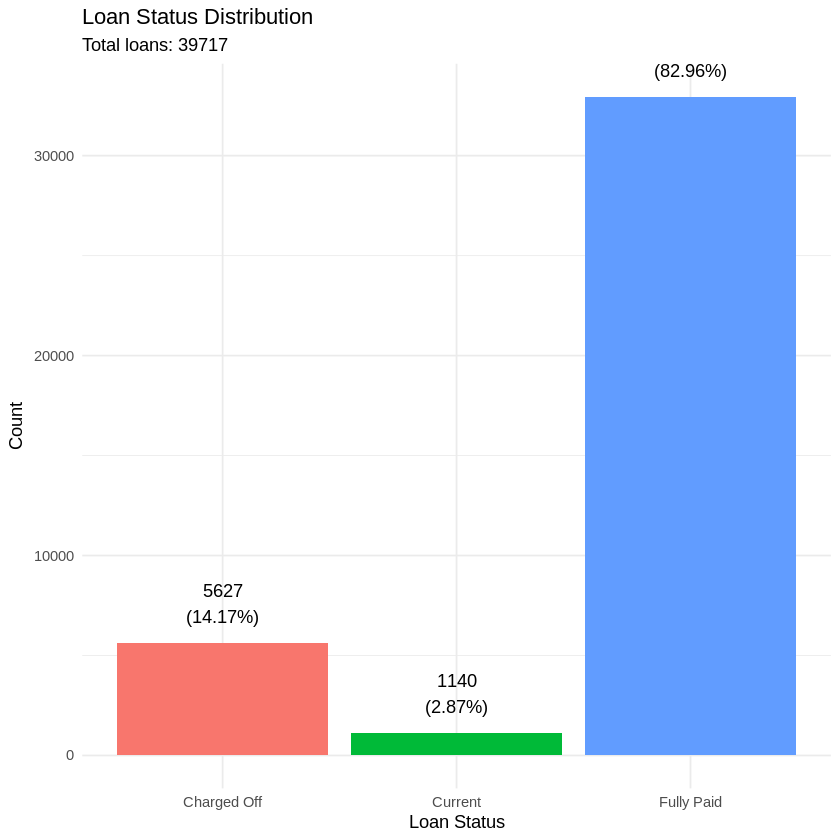

In [ ]:
# Check class distribution
class_distribution <- loan_data %>%
  count(loan_status) %>%
  mutate(
    percentage = round(n / sum(n) * 100, 2),
    percentage_formatted = paste0(percentage, "%")
  )

print(class_distribution)

# Visualize the class imbalance
library(ggplot2)

ggplot(class_distribution, aes(x = loan_status, y = n, fill = loan_status)) +
  geom_bar(stat = "identity") +
  geom_text(aes(label = paste0(n, "\n(", percentage_formatted, ")")),
            vjust = -0.5) +
  theme_minimal() +
  labs(
    title = "Loan Status Distribution",
    subtitle = paste0("Total loans: ", nrow(loan_data)),
    x = "Loan Status",
    y = "Count"
  ) +
  theme(legend.position = "none")

# Calculate imbalance ratio
charged_off_count <- sum(loan_data$loan_status == "Charged Off")
fully_paid_count <- sum(loan_data$loan_status == "Fully Paid")
imbalance_ratio <- fully_paid_count / charged_off_count

cat("\nImbalance Analysis:\n")
cat("Fully Paid count:", fully_paid_count, "\n")
cat("Charged Off count:", charged_off_count, "\n")
cat("Ratio (Fully Paid : Charged Off):", round(imbalance_ratio, 2), ": 1\n")

NEXT STAGE

In [ ]:

 dim(loan_data)

[1] 39717    51

In [ ]:
library(dplyr)

numeric_cols <- loan_data %>%
  select(where(is.numeric))

#cchecking zero variance
zero_var_cols <- names(numeric_cols)[sapply(numeric_cols, function(x)
  length(unique(na.omit(x))) <= 1
)]

print(zero_var_cols)

[1] "collections_12_mths_ex_med"


Removing Zero Variance Column

In [ ]:

loan_data <- loan_data %>%
  select(-collections_12_mths_ex_med)

"collections_12_mths_ex_med" %in% names(loan_data)

[1] FALSE

In [ ]:
names(loan_data)

[1] "id"                          "member_id"                  
 [3] "loan_amnt"                   "funded_amnt"                
 [5] "funded_amnt_inv"             "term_months"                
 [7] "installment"                 "grade"                      
 [9] "sub_grade"                   "emp_length_years"           
[11] "home_ownership"              "annual_inc"                 
[13] "verification_status"         "issue_d"                    
[15] "loan_status"                 "purpose"                    
[17] "zip_code"                    "addr_state"                 
[19] "dti"                         "delinq_2yrs"                
[21] "earliest_cr_line"            "inq_last_6mths"             
[23] "mths_since_last_delinq"      "mths_since_last_record"     
[25] "open_acc"                    "revol_bal"                  
[27] "revol_util_percent"          "total_acc"                  
[29] "out_prncp"                   "out_prncp_inv"              
[31] "total_pymnt"                 "total_pymnt_inv"            
[33] "total_rec_prncp"             "total_rec_int"              
[35] "total_rec_late_fee"          "recoveries"                 
[37] "collection_recovery_fee"     "last_pymnt_d"               
[39] "last_pymnt_amnt"             "last_credit_pull_d"         
[41] "pub_rec_bankruptcies_binary" "never_delinq"               
[43] "has_public_record"           "credit_history_months"      
[45] "issue_year"                  "int_rate_percent"           
[47] "payment_to_income_ratio"     "avg_credit_per_account"     
[49] "debt_burden_ratio"           "delinq_rate"

CREATING TARGET

In [ ]:
loan_data <- loan_data %>%
  filter(loan_status != "Current") %>%
  mutate(target = ifelse(loan_status == "Charged Off", 1, 0))

REMOVE LEAKAGE AND REDUNDANT COLUMNS

In [ ]:
loan_data <- loan_data %>% select(-c(

  out_prncp, #leakage
  out_prncp_inv, #leakage
  total_pymnt, #leakage
  total_pymnt_inv,#leakage
  total_rec_prncp, #leakage
  total_rec_int, #leakage
  total_rec_late_fee,#leakage
  recoveries, #leakage
  collection_recovery_fee,#leakage
  last_pymnt_d, #leakage
  last_pymnt_amnt, #leakage
  last_credit_pull_d,#leakage

  id, member_id, # no added value
  loan_status, #we have target now
  issue_d, # vintage effect
  earliest_cr_line, #we have credit history month
  zip_code, #many values and state area covers this
  grade, #we have sub grade
  funded_amnt, #highly correlated to loan_amnt
  funded_amnt_inv, #same as funded_amnt
  issue_year   # vintage effect
))

LABEL ENCODING FOR SUB_GRADE. ORDINAL ENCODING

In [ ]:
sub_levels <- as.vector(t(outer(LETTERS[1:7], 1:5, paste0)))           # A1,A2,...,G5
loan_data$sub_grade_numeric <- match(loan_data$sub_grade, sub_levels)

In [ ]:
loan_data <- loan_data %>% select(-sub_grade)

FEATURE ENGINEERING

In [ ]:
loan_data <- loan_data %>%
  mutate(
    inq_open_ratio         = inq_last_6mths / (open_acc + 1))


In [ ]:
loan_data <- loan_data %>%
  mutate(loan_to_income         = loan_amnt / annual_inc)

In [ ]:
loan_data <- loan_data %>%
  mutate(debt_service_ratio     = (installment + (dti/100 * annual_inc/12)) / (annual_inc/12))

In [ ]:
loan_data <- loan_data %>%
  mutate(residual_income        = (annual_inc/12) - installment - (dti/100 * annual_inc/12))

In [ ]:
loan_data <- loan_data %>%
  mutate(total_debt             = dti * annual_inc / 100)

In [ ]:
loan_data <- loan_data %>%
  mutate(dti_squared            = dti^2)

In [ ]:
loan_data <- loan_data %>%
  mutate(term_grade_interaction = term_months * sub_grade_numeric)

In [ ]:
loan_data <- loan_data %>%
  mutate(grade_dti_risk         = sub_grade_numeric * (dti / 100))

In [ ]:
loan_data <- loan_data %>%
  mutate(income_history_score   = (annual_inc / 10000) * (credit_history_months / 12))

In [ ]:
loan_data <- loan_data %>%
  mutate(income_history_ratio   = annual_inc / (credit_history_months + 1))

In [ ]:
loan_data <- loan_data %>%
  mutate(util_stress            = revol_util_percent * (delinq_2yrs + 1))

In [ ]:
loan_data <- loan_data %>%
  mutate(high_util_flag         = as.integer(revol_util_percent > 80))

In [ ]:
loan_data <- loan_data %>%
  mutate(recent_stress =
      as.integer(inq_last_6mths > 2) +
      as.integer(delinq_2yrs > 0) +
      as.integer(mths_since_last_delinq < 12 & !is.na(mths_since_last_delinq)) +
      as.integer(revol_util_percent > 80))

In [ ]:
loan_data <- loan_data %>%
  mutate(risk_index =
      (sub_grade_numeric / 35) * 0.25 +
      (inq_open_ratio / 2)     * 0.20 +
      (dti / 40)               * 0.15 +
      (loan_to_income)         * 0.15 +
      as.numeric(term_months == 60) * 0.15 +
      (delinq_2yrs / 5)        * 0.10)

In [ ]:
dim(loan_data)

[1] 38577    43

STATISTICAL TESTS

Chi square test for categorical features

In [ ]:
cat_feats <- intersect(c("purpose","verification_status","home_ownership"), names(loan_data))

cat_stats <- bind_rows(lapply(cat_feats, function(f){
  tbl <- table(loan_data[[f]], loan_data$target)
  if(nrow(tbl)>1 && ncol(tbl)>1) {
    ch <- chisq.test(tbl)
    data.frame(feature=f,
               chi_sq=round(ch$statistic,1),
               p_value=signif(ch$p.value,3))
  }
})) %>% arrange(p_value)

cat("\n=== CATEGORICAL FEATURES (Chi-square) ===\n")
print(cat_stats, row.names=FALSE)


=== CATEGORICAL FEATURES (Chi-square) ===
             feature chi_sq  p_value
             purpose  378.9 6.21e-73
 verification_status   89.9 3.08e-20
      home_ownership   21.4 8.51e-05


CORRELATIONS

In [ ]:
install.packages("corrplot")
library(corrplot)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

corrplot 0.95 loaded




=== TOP 10 CORRELATIONS WITH TARGET ===
                 feature    pearson   spearman
              risk_index 0.23037926 0.22152838
  term_grade_interaction 0.22046310 0.21722896
        int_rate_percent 0.21139019 0.20330308
       sub_grade_numeric 0.20532025 0.20100572
             term_months 0.17348668 0.17348668
          grade_dti_risk 0.16792814 0.16537527
          loan_to_income 0.11811218 0.10455903
      revol_util_percent 0.09987473 0.09983087
             util_stress 0.08483457 0.09953235
 payment_to_income_ratio 0.08366134 0.08010152


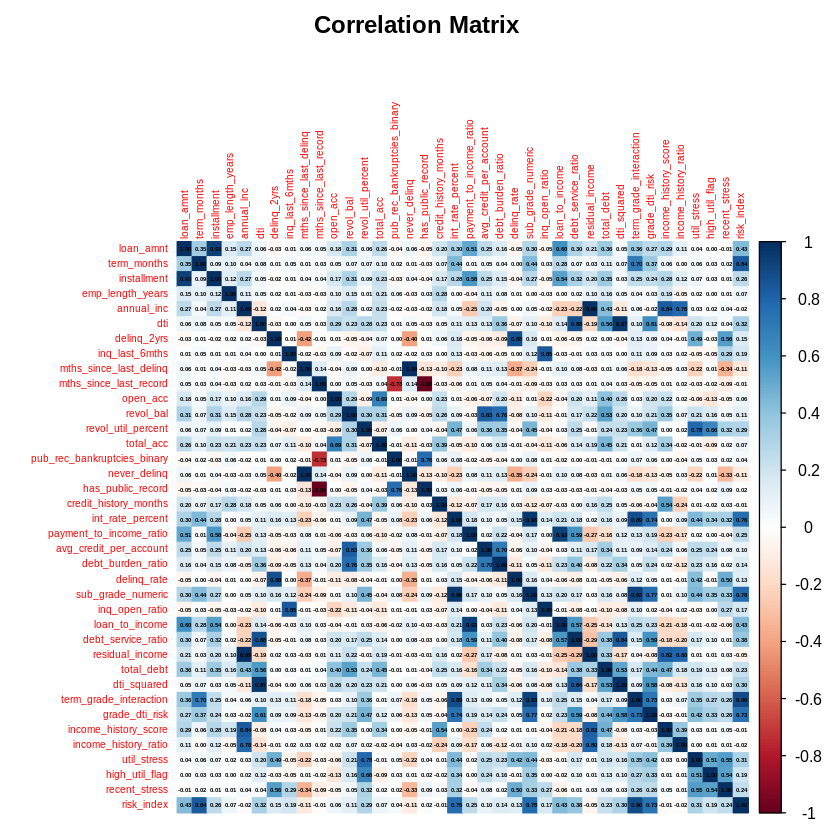

In [ ]:
numeric_cols <- loan_data %>% select(where(is.numeric), -target)
correlations <- data.frame(
  feature = names(numeric_cols),
  pearson = sapply(names(numeric_cols), function(f) cor(loan_data[[f]], loan_data$target, use="complete.obs")),
  spearman = sapply(names(numeric_cols), function(f) cor(loan_data[[f]], loan_data$target, method="spearman", use="complete.obs"))
) %>% filter(!is.na(pearson)) %>% arrange(desc(abs(pearson)))

cat("\n=== TOP 10 CORRELATIONS WITH TARGET ===\n")
print(head(correlations, 10), row.names=FALSE)
cor_matrix <- cor(numeric_cols)
# Heatmap
corrplot(cor_matrix,
         method = "color",
         type = "full",
         tl.cex = 0.5,
         number.cex = 0.3,
         addCoef.col = "black",
         diag = TRUE,
         title = "Correlation Matrix ",
         mar = c(0,0,2,0))

INSIGHTFUL PLOTS

SUB GRADE TREND

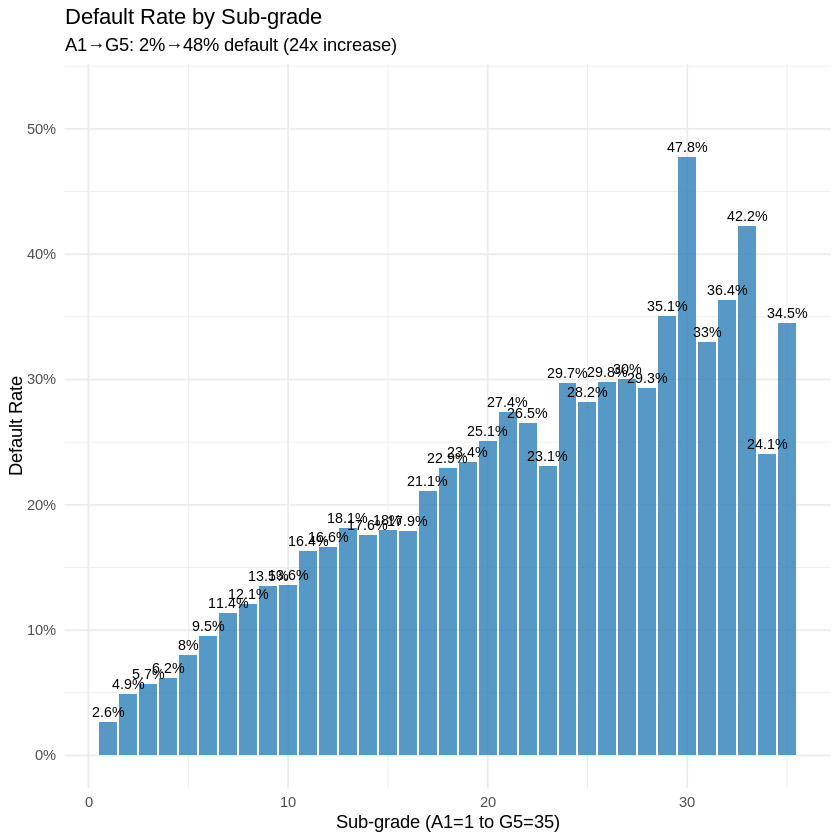

In [ ]:
subgrade_default <- loan_data %>%
  group_by(sub_grade_numeric) %>%
  summarise(n=n(), default_rate=mean(target, na.rm=T)) %>%
  filter(!is.na(sub_grade_numeric))

p1 <- ggplot(subgrade_default, aes(sub_grade_numeric, default_rate)) +
  geom_col(fill="#2c7fb8", alpha=0.8) +
  geom_text(aes(label=paste0(round(default_rate*100,1),"%")), vjust=-0.5, size=3) +
  scale_y_continuous(labels=scales::percent, limits=c(0, max(subgrade_default$default_rate)*1.1)) +
  labs(title="Default Rate by Sub-grade",
       subtitle="A1→G5: 2%→48% default (24x increase)",
       x="Sub-grade (A1=1 to G5=35)",
       y="Default Rate") +
  theme_minimal()
print(p1)

PURPOSE-RISK

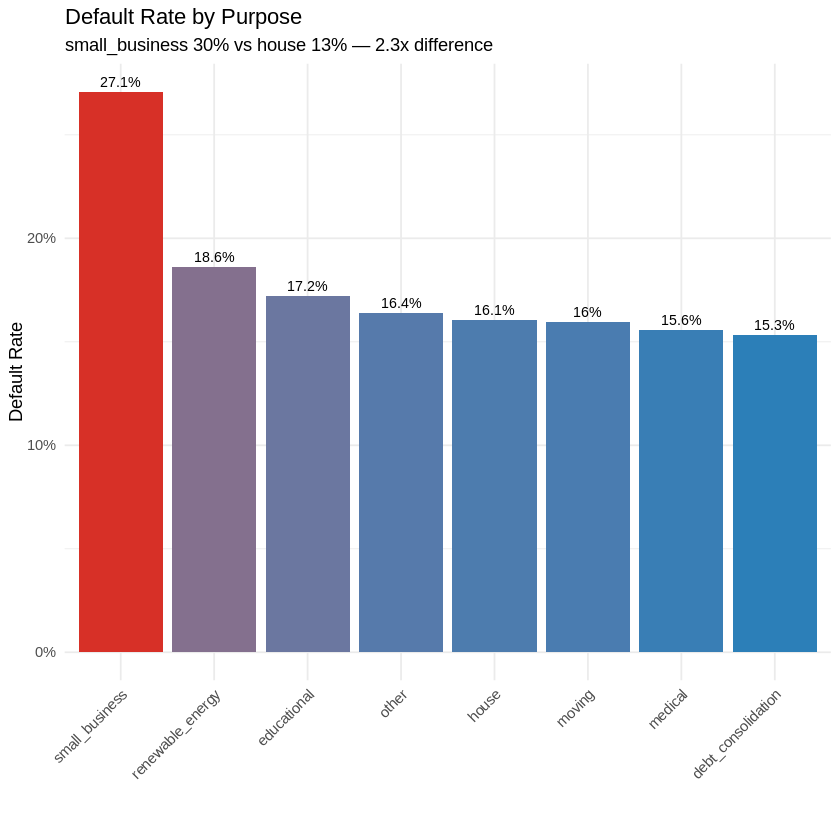

In [ ]:
purpose_default <- loan_data %>%
  group_by(purpose) %>%
  summarise(n=n(), default_rate=mean(target, na.rm=T)) %>%
  arrange(desc(default_rate))

p2 <- ggplot(head(purpose_default, 8), aes(reorder(purpose, -default_rate), default_rate, fill=default_rate)) +
  geom_col() +
  geom_text(aes(label=paste0(round(default_rate*100,1),"%")), vjust=-0.5, size=3) +
  scale_fill_gradient(low="#2c7fb8", high="#d73027") +
  scale_y_continuous(labels=scales::percent) +
  labs(title="Default Rate by Purpose",
       subtitle="small_business 30% vs house 13% — 2.3x difference",
       x="",
       y="Default Rate") +
  theme_minimal() +
  theme(axis.text.x=element_text(angle=45,hjust=1), legend.position="none")
print(p2)

DESPERATION SIGNAL: INQUIRY/OPEN RATIO

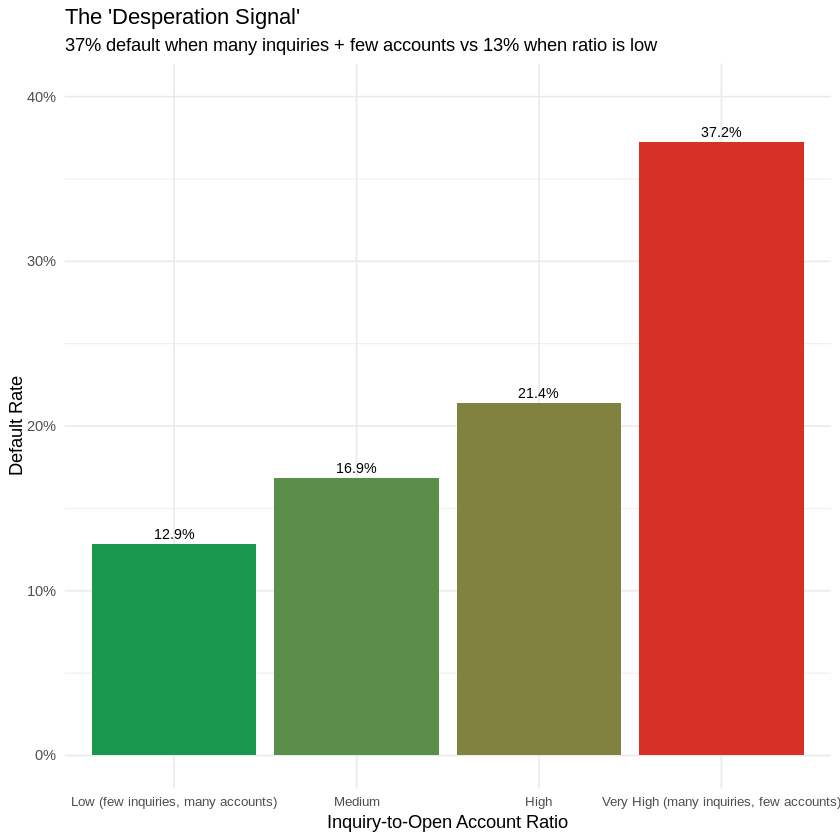

In [ ]:
loan_data <- loan_data %>%
  mutate(inq_open_ratio = inq_last_6mths/(open_acc+1))

inq_risk <- loan_data %>%
  mutate(risk_group = case_when(
    inq_open_ratio < 0.1 ~ "Low (few inquiries, many accounts)",
    inq_open_ratio < 0.5 ~ "Medium",
    inq_open_ratio < 1.0 ~ "High",
    TRUE ~ "Very High (many inquiries, few accounts)"
  )) %>%
  group_by(risk_group) %>%
  summarise(n=n(), default_rate=mean(target, na.rm=T)) %>%
  mutate(risk_group = factor(risk_group, levels=c("Low (few inquiries, many accounts)","Medium","High","Very High (many inquiries, few accounts)")))

p3 <- ggplot(inq_risk, aes(risk_group, default_rate, fill=default_rate)) +
  geom_col() +
  geom_text(aes(label=paste0(round(default_rate*100,1),"%")), vjust=-0.5, size=3) +
  scale_fill_gradient(low="#1a9850", high="#d73027") +
  scale_y_continuous(labels=scales::percent, limits=c(0,0.40)) +
  labs(title="The 'Desperation Signal'",
       subtitle="37% default when many inquiries + few accounts vs 13% when ratio is low",
       x="Inquiry-to-Open Account Ratio",
       y="Default Rate") +
  theme_minimal() +
  theme(axis.text.x=element_text(size=8), legend.position="none")
print(p3)


TERM - SUB-GRADE HEATMAP

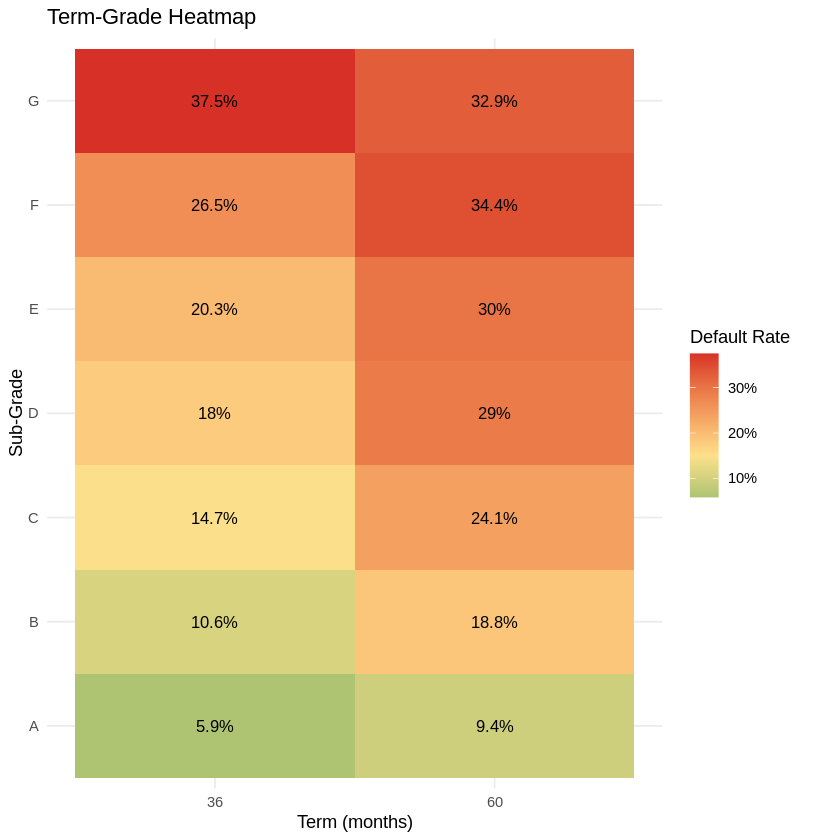

In [ ]:
term_grade <- loan_data %>%
  mutate(grade_group = case_when(
    sub_grade_numeric <= 5 ~ "A",
    sub_grade_numeric <= 10 ~ "B",
    sub_grade_numeric <= 15 ~ "C",
    sub_grade_numeric <= 20 ~ "D",
    sub_grade_numeric <= 25 ~ "E",
    sub_grade_numeric <= 30 ~ "F",
    TRUE ~ "G"
  )) %>%
  group_by(term_months, grade_group) %>%
  summarise(n=n(), default_rate=mean(target, na.rm=T), .groups="drop") %>%
  filter(n>=30)

p4 <- ggplot(term_grade, aes(x=as.factor(term_months), y=grade_group, fill=default_rate)) +
  geom_tile() +
  geom_text(aes(label=paste0(round(default_rate*100,1),"%")), size=3.5) +
  scale_fill_gradient2(low="#1a9850", mid="#fee08b", high="#d73027", midpoint=0.15, labels=scales::percent) +
  labs(title="Term-Grade Heatmap",
       x="Term (months)",
       y="Sub-Grade",
       fill="Default Rate") +
  theme_minimal()
print(p4)

STATE-INCOME INTERACTION

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


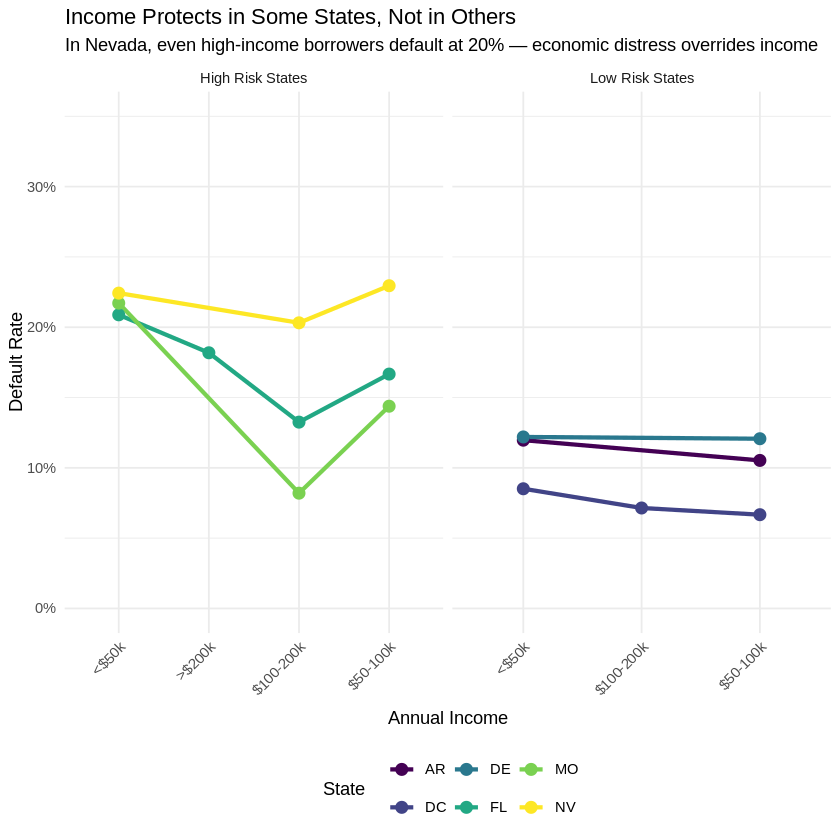

In [ ]:
high_states <- loan_data %>%
  group_by(addr_state) %>%
  summarise(default_rate=mean(target, na.rm=T), n=n()) %>%
  filter(n>=100) %>%
  arrange(desc(default_rate)) %>%
  head(3) %>%
  pull(addr_state)

low_states <- loan_data %>%
  group_by(addr_state) %>%
  summarise(default_rate=mean(target, na.rm=T), n=n()) %>%
  filter(n>=100) %>%
  arrange(default_rate) %>%
  head(3) %>%
  pull(addr_state)

selected_states <- c(high_states, low_states)

state_income <- loan_data %>%
  filter(addr_state %in% selected_states) %>%
  mutate(
    income_bucket = case_when(
      annual_inc < 50000 ~ "<$50k",
      annual_inc < 100000 ~ "$50-100k",
      annual_inc < 200000 ~ "$100-200k",
      TRUE ~ ">$200k"
    ),
    state_group = ifelse(addr_state %in% high_states, "High Risk States", "Low Risk States")
  ) %>%
  group_by(addr_state, income_bucket, state_group) %>%
  summarise(n=n(), default_rate=mean(target, na.rm=T), .groups="drop") %>%
  filter(n>=30)

p5 <- ggplot(state_income, aes(x=income_bucket, y=default_rate, color=addr_state, group=addr_state)) +
  geom_line(size=1.2) +
  geom_point(size=3) +
  facet_wrap(~state_group, scales="free_x") +
  scale_color_viridis_d() +
  scale_y_continuous(labels=scales::percent, limits=c(0,0.35)) +
  labs(title="Income Protects in Some States, Not in Others",
       subtitle="In Nevada, even high-income borrowers default at 20% — economic distress overrides income",
       x="Annual Income",
       y="Default Rate",
       color="State") +
  theme_minimal() +
  theme(axis.text.x=element_text(angle=45,hjust=1), legend.position="bottom")
print(p5)


Skewness Check

In [ ]:
library(dplyr)

skewness <- function(x, na.rm = TRUE) {
  if (na.rm) x <- x[!is.na(x)]
  n <- length(x); m <- mean(x)
  (sum((x - m)^3) / n) / (sum((x - m)^2) / n)^(3/2)
}

# take ALL numeric columns, auto-drop binary/low-cardinality (not hard-coded)
num_df <- loan_data %>% select(where(is.numeric))
cont   <- names(num_df)[sapply(num_df, function(x) length(unique(na.omit(x))) > 20)]
cont   <- setdiff(cont, "target")

skew_report <- data.frame(
  feature  = cont,
  skewness = round(sapply(cont, function(c) skewness(loan_data[[c]], na.rm = TRUE)), 3),
  min      = round(sapply(cont, function(c) min(loan_data[[c]], na.rm = TRUE)), 2)
) %>%
  mutate(log_eligible = ifelse(skewness > 0.75 & min >= 0, "yes", "no")) %>%
  arrange(desc(abs(skewness)))

print(skew_report, row.names = FALSE)

                 feature skewness     min log_eligible
    income_history_ratio   49.458   17.90          yes
         residual_income   35.846  245.72          yes
              annual_inc   31.197 4000.00          yes
    income_history_score   12.028    1.23          yes
             delinq_rate    7.382    0.00          yes
  avg_credit_per_account    4.415    0.00          yes
              total_debt    3.484    0.00          yes
  mths_since_last_record   -3.354    0.00           no
               revol_bal    3.212    0.00          yes
          inq_open_ratio    2.574    0.00          yes
       debt_burden_ratio    2.460    0.00          yes
             util_stress    2.129    0.00          yes
  term_grade_interaction    1.463   36.00          yes
          grade_dti_risk    1.315    0.00          yes
   credit_history_months    1.178   36.00          yes
             installment    1.150   15.69          yes
               loan_amnt    1.078  500.00          yes
 payment_t

K MEANS CLUSTERING WITH ELBOW METHOD

In [ ]:
clust_features <- intersect(c("sub_grade_numeric","int_rate_percent","dti","annual_inc",
  "loan_amnt","revol_util_percent","delinq_2yrs","inq_last_6mths",
  "credit_history_months","term_months","inq_open_ratio"), names(loan_data))

clust_df <- loan_data %>% select(all_of(clust_features), target) %>% na.omit()

Log transform skewed money columns

In [ ]:
for (c in intersect(c("annual_inc","loan_amnt","revol_bal"), names(clust_df)))
  clust_df[[c]] <- log1p(clust_df[[c]])

clust_X      <- clust_df %>% select(-target)
clust_scaled <- scale(clust_X)

FIND OPTIMAL K USING ELBOW METHOD

In [ ]:
set.seed(42)
wss <- sapply(1:10, function(k)
  kmeans(clust_scaled, centers=k, nstart=25, iter.max=100)$tot.withinss)

Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”
Warning message:
“Quick-T

ELBOW PLOT

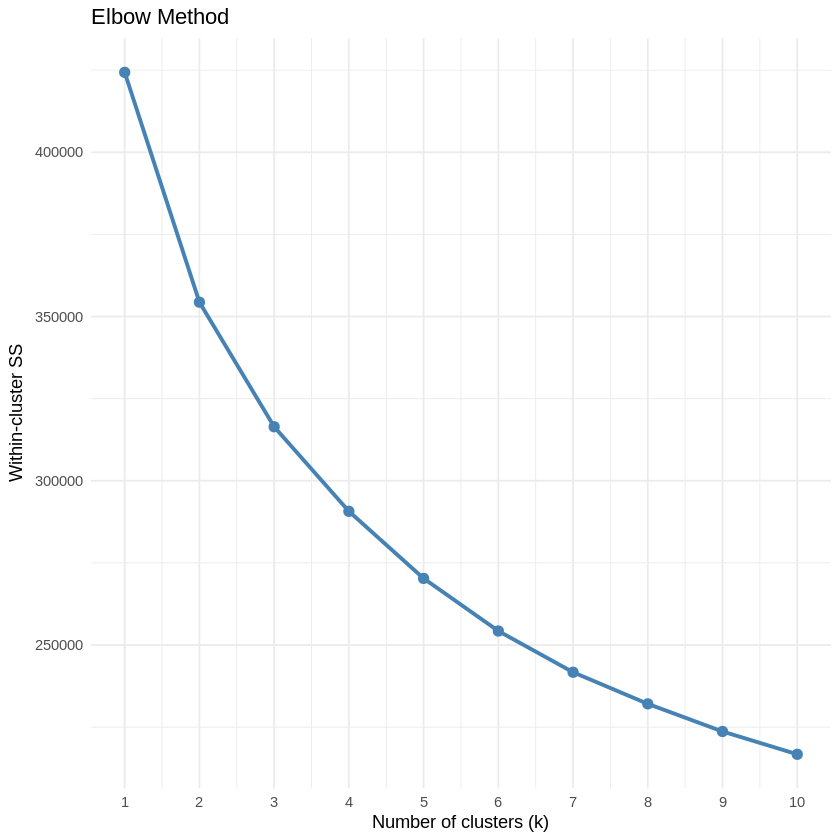

In [ ]:
print(ggplot(data.frame(k=1:10, wss=wss), aes(k, wss)) +
  geom_line(color="steelblue", size=1.1) + geom_point(color="steelblue", size=2.5) +
  scale_x_continuous(breaks=1:10) +
  labs(title="Elbow Method", x="Number of clusters (k)", y="Within-cluster SS") + theme_minimal())

In [ ]:
library(cluster)

SILHOUETTE METHOD

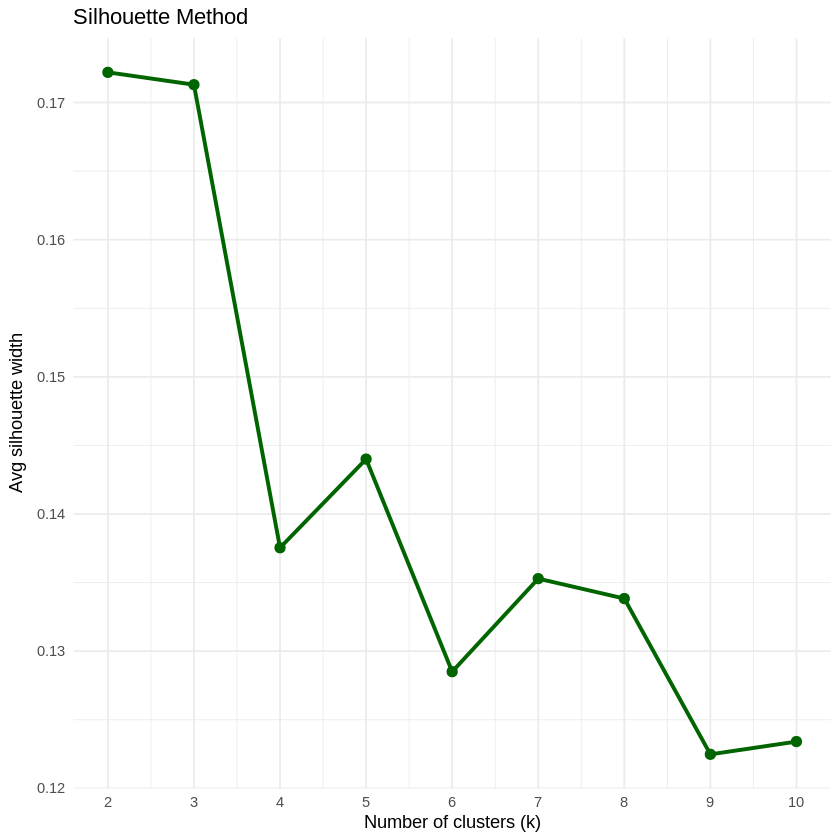

In [ ]:
set.seed(42); sidx <- sample(nrow(clust_scaled), 3000)
sil <- sapply(2:10, function(k) {
  km <- kmeans(clust_scaled[sidx,], centers=k, nstart=10, iter.max=100)
  mean(silhouette(km$cluster, dist(clust_scaled[sidx,]))[,3])
})

print(ggplot(data.frame(k=2:10, sil=sil), aes(k, sil)) +
  geom_line(color="darkgreen", size=1.1) + geom_point(color="darkgreen", size=2.5) +
  scale_x_continuous(breaks=2:10) +
  labs(title="Silhouette Method", x="Number of clusters (k)", y="Avg silhouette width") + theme_minimal())

RUN K MEANS WITH K=3

In [ ]:
set.seed(42)
km <- kmeans(clust_scaled, centers=3, nstart=25, iter.max=100)
clust_df$cluster <- factor(km$cluster)

Warning message:
“Quick-TRANSfer stage steps exceeded maximum (= 1928850)”


Profile clusters

In [ ]:
profile <- clust_df %>% group_by(cluster) %>%
  summarise(n=n(), default_rate=round(mean(target)*100,1),
    sub_grade=round(mean(sub_grade_numeric),1), int_rate=round(mean(int_rate_percent),1),
    dti=round(mean(dti),1), income=round(expm1(mean(annual_inc))),
    loan=round(expm1(mean(loan_amnt))), revol_util=round(mean(revol_util_percent),1),
    delinq=round(mean(delinq_2yrs),2), cr_hist_yrs=round(mean(credit_history_months)/12,1),
    .groups="drop") %>%
  mutate(risk = case_when(default_rate>18 ~ "High Risk",
                          default_rate>12 ~ "Medium Risk", TRUE ~ "Low Risk"))
cat("\n=== CLUSTER PROFILES ===\n"); print(as.data.frame(profile), row.names=FALSE)


=== CLUSTER PROFILES ===
 cluster     n default_rate sub_grade int_rate  dti income  loan revol_util
       1 11570         22.6      17.9     15.7 15.1  68191 13207       65.9
       2  7639         17.1      10.9     12.1 12.2  52245  7020       44.1
       3 19368          8.8       6.5      9.6 12.6  55002  7395       40.2
 delinq cr_hist_yrs        risk
   0.22        14.1   High Risk
   0.16        12.4 Medium Risk
   0.10        14.0    Low Risk


CLUSTER VISUALIZATION
1: PCA PROJECTION

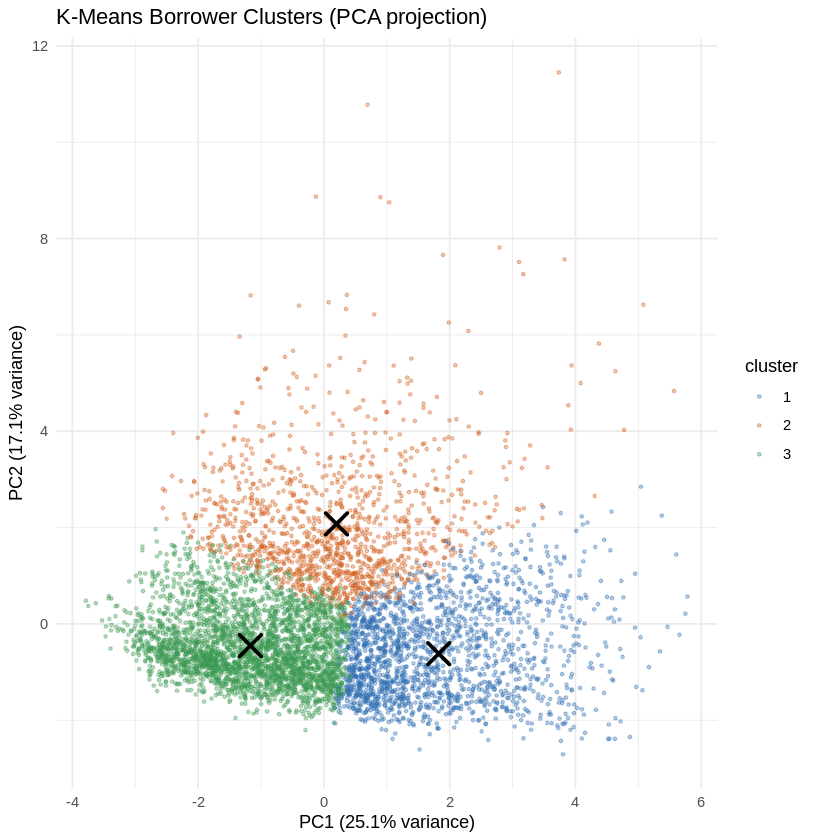

In [ ]:
pca <- prcomp(clust_scaled)
ev  <- round(summary(pca)$importance[2,1:2]*100, 1)
pd  <- data.frame(PC1=pca$x[,1], PC2=pca$x[,2], cluster=clust_df$cluster)
cen <- pd %>% group_by(cluster) %>% summarise(PC1=mean(PC1), PC2=mean(PC2), .groups="drop")
set.seed(0); pd_s <- pd[sample(nrow(pd), 6000),]

print(ggplot(pd_s, aes(PC1, PC2, color=cluster)) +
  geom_point(alpha=0.35, size=0.7) +
  geom_point(data=cen, aes(PC1, PC2), color="black", shape=4, size=5, stroke=1.6, inherit.aes=FALSE) +
  scale_color_manual(values=c("#2f6fb3","#d1611f","#3a9a52")) +
  labs(title="K-Means Borrower Clusters (PCA projection)",
       x=sprintf("PC1 (%.1f%% variance)", ev[1]), y=sprintf("PC2 (%.1f%% variance)", ev[2])) +
  theme_minimal())


STANDARDIZED-MEAN HEATMAP

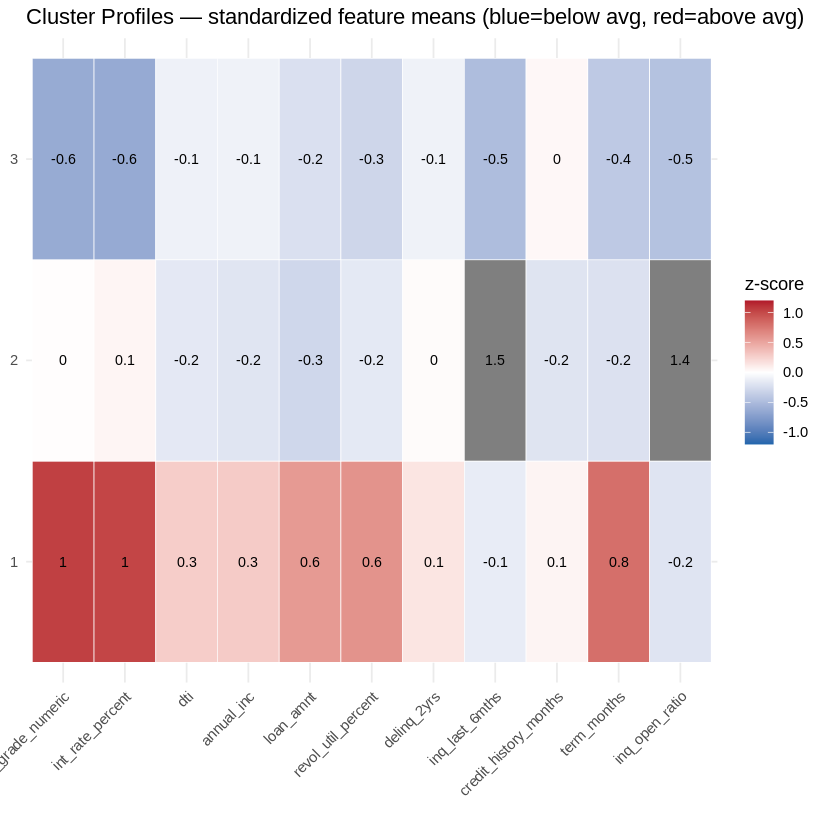

In [ ]:
zmat <- as.data.frame(clust_scaled) %>% mutate(cluster=clust_df$cluster) %>%
  group_by(cluster) %>% summarise(across(everything(), mean), .groups="drop") %>%
  pivot_longer(-cluster, names_to="feature", values_to="z")
zmat$feature <- factor(zmat$feature, levels=colnames(clust_scaled))

print(ggplot(zmat, aes(feature, cluster, fill=z)) +
  geom_tile(color="white") + geom_text(aes(label=round(z,1)), size=3) +
  scale_fill_gradient2(low="#2166ac", mid="white", high="#b2182b", midpoint=0, limits=c(-1.2,1.2)) +
  labs(title="Cluster Profiles — standardized feature means (blue=below avg, red=above avg)",
       x=NULL, y=NULL, fill="z-score") +
  theme_minimal() + theme(axis.text.x=element_text(angle=45, hjust=1)))

OUTLIERS DETECTION USING BOXPLOT

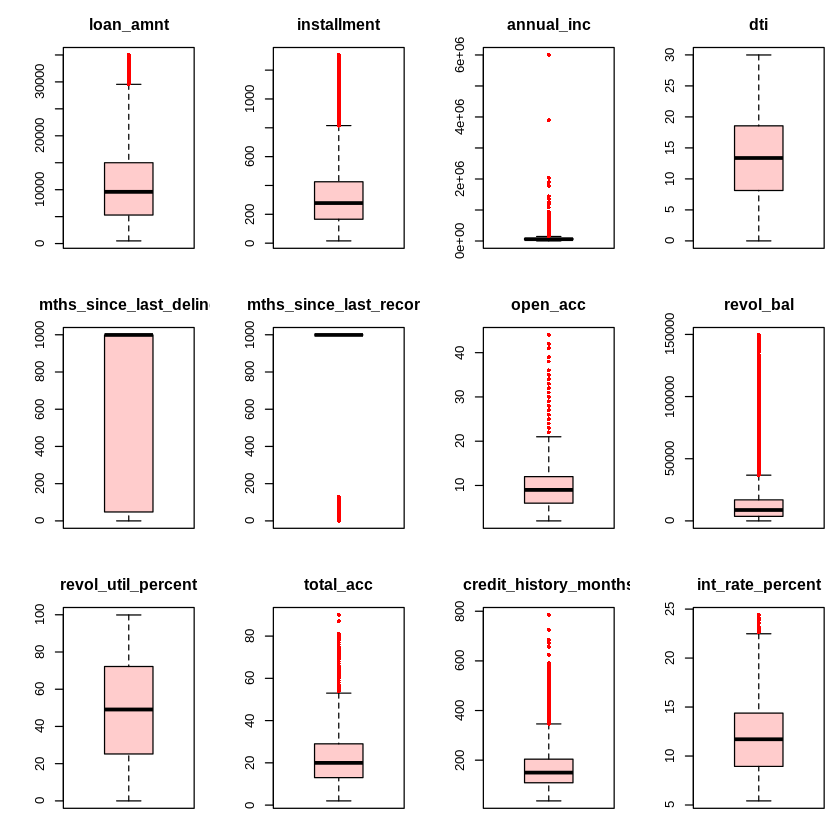

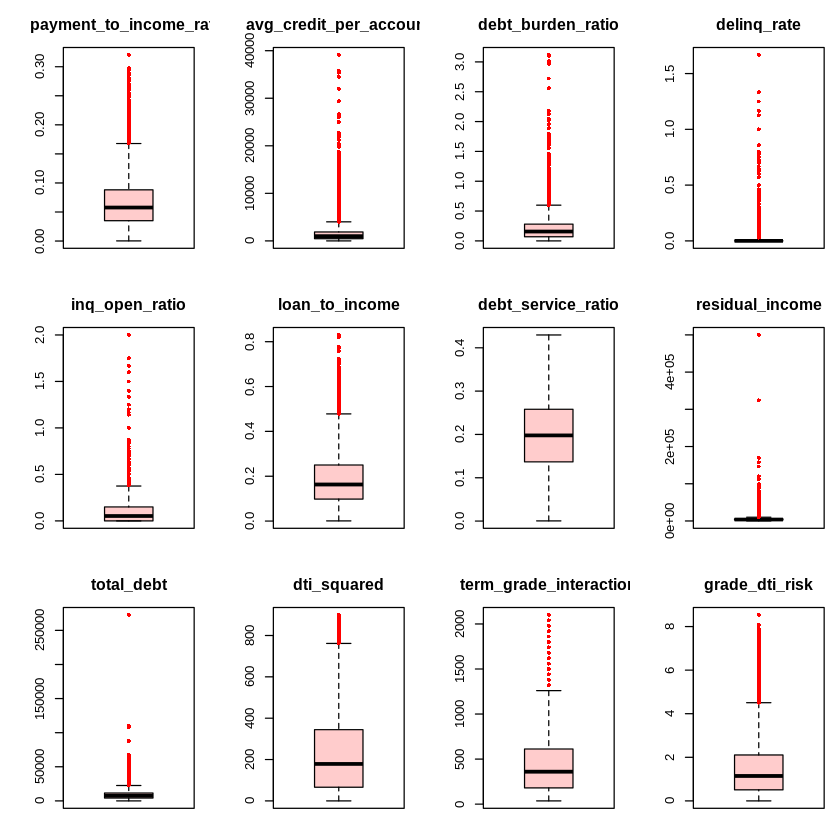

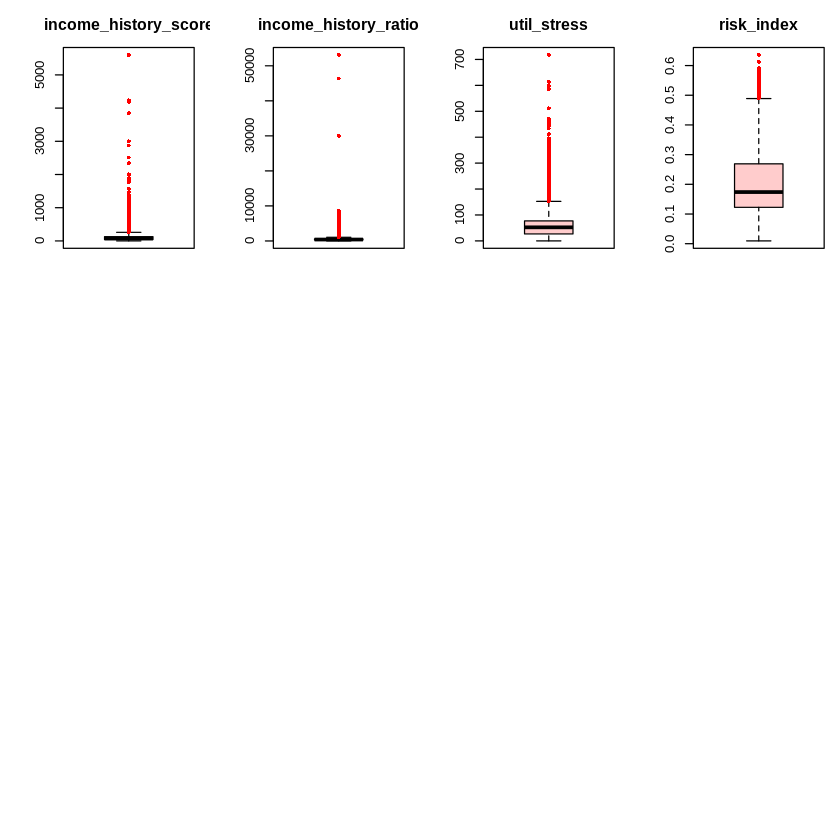

In [ ]:

exclude <- c("target", "sub_grade_numeric", "term_months", "high_util_flag",
             "recent_stress", "never_delinq", "pub_rec_bankruptcies_binary")

num_df <- loan_data %>% select(where(is.numeric))
cont_cols <- names(num_df)[sapply(num_df, function(x) length(unique(na.omit(x))) > 20)]
cont_cols <- setdiff(cont_cols, exclude)

par(mfrow = c(3, 4), mar = c(2, 4, 3, 1))  # 3 rows, 4 columns
for (col in cont_cols) {
  boxplot(loan_data[[col]],
          main = paste(col),
          col = "#FFCCCC",
          outcol = "red",
          outpch = 16)
}
par(mfrow = c(1, 1))

In [ ]:
skewness <- function(x, na.rm = TRUE) {
  if (na.rm) x <- x[!is.na(x)]
  n <- length(x); m <- mean(x)
  (sum((x - m)^3)/n) / (sum((x - m)^2)/n)^(3/2)
}

exclude <- c("target","sub_grade_numeric","term_months","high_util_flag","recent_stress",
             "never_delinq","pub_rec_bankruptcies_binary","has_public_record",
             "mths_since_last_delinq","mths_since_last_record")   # sentinels: leave as-is
num_df    <- loan_data %>% select(where(is.numeric))
cont_cols <- names(num_df)[sapply(num_df, function(x) length(unique(na.omit(x))) > 20)]
cont_cols <- setdiff(cont_cols, exclude)
skew_val  <- sapply(cont_cols, function(c) skewness(loan_data[[c]], na.rm = TRUE))
min_val   <- sapply(cont_cols, function(c) min(loan_data[[c]], na.rm = TRUE))
to_log    <- cont_cols[skew_val > 0.75 & min_val >= 0]
print(to_log)

for (c in to_log) loan_data[[c]] <- log1p(loan_data[[c]])

 [1] "loan_amnt"               "installment"            
 [3] "annual_inc"              "open_acc"               
 [5] "revol_bal"               "total_acc"              
 [7] "credit_history_months"   "payment_to_income_ratio"
 [9] "avg_credit_per_account"  "debt_burden_ratio"      
[11] "delinq_rate"             "inq_open_ratio"         
[13] "loan_to_income"          "residual_income"        
[15] "total_debt"              "dti_squared"            
[17] "term_grade_interaction"  "grade_dti_risk"         
[19] "income_history_score"    "income_history_ratio"   
[21] "util_stress"             "risk_index"             


TRAIN TEST SPLIT

In [ ]:
set.seed(42)
loan_data$.row <- seq_len(nrow(loan_data))
train_idx  <- loan_data %>% group_by(target) %>% slice_sample(prop = 0.8) %>% pull(.row)
train_data <- loan_data %>% filter(.row %in% train_idx)  %>% select(-.row)
test_data  <- loan_data %>% filter(!(.row %in% train_idx))
test_ids   <- test_data$.row
test_data  <- test_data %>% select(-.row)
loan_data$.row <- NULL
cat(sprintf("train: %d (default %.3f) | test: %d (default %.3f)\n",
            nrow(train_data), mean(train_data$target),
            nrow(test_data),  mean(test_data$target)))


train: 30861 (default 0.146) | test: 7716 (default 0.146)


HISTOGRAM FOR TRAINED ONLY

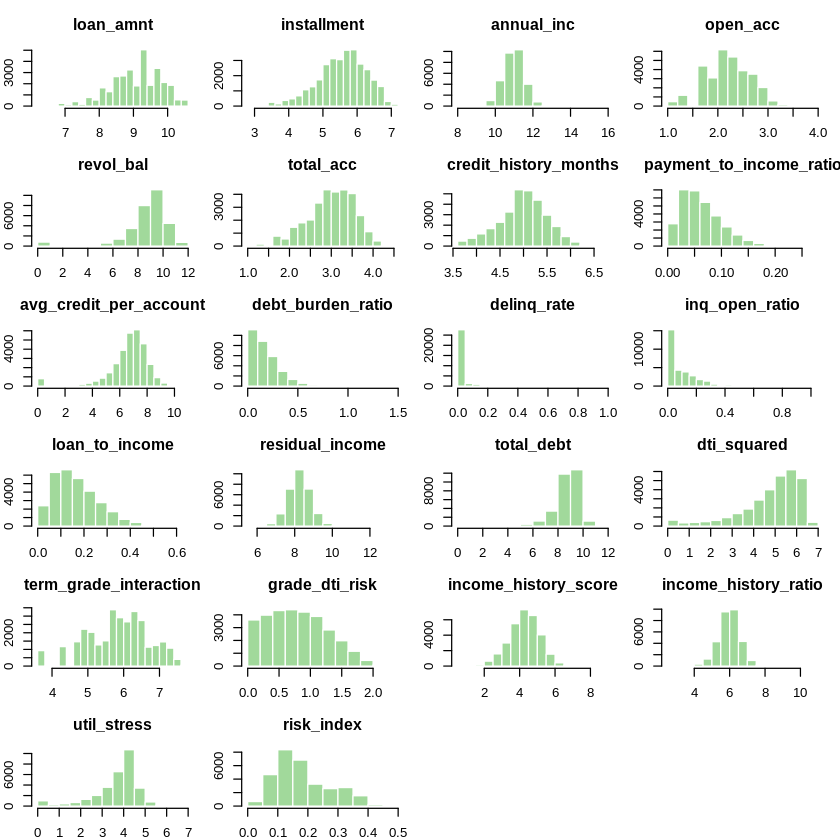

In [ ]:
n <- length(to_log); par(mfrow = c(ceiling(n/4), 4), mar = c(2,2,3,1))
for (c in to_log) hist(train_data[[c]], main = c, col = "#a1d99b", border = "white", xlab = "")
par(mfrow = c(1,1))

We can work with this data. dti squared is already squared value so using sqrt is redundant.

SCALING (z score normalization)




In [ ]:
num_cols <- names(train_data)[sapply(train_data, is.numeric)]
num_cols <- setdiff(num_cols, "target")

train_means <- sapply(train_data[num_cols], mean, na.rm = TRUE)
train_sds   <- sapply(train_data[num_cols], sd,   na.rm = TRUE)
train_sds[train_sds == 0] <- 1   #THIS is for zero-variance column

train_data[num_cols] <- scale(train_data[num_cols], center = train_means, scale = train_sds)
test_data[num_cols]  <- scale(test_data[num_cols],  center = train_means, scale = train_sds)


cat("train mean", round(mean(colMeans(train_data[num_cols])), 4), "\n")
cat("train sd", round(mean(apply(train_data[num_cols], 2, sd)), 4), "\n")

train mean 0 
train sd 1 


In [ ]:
glob <- mean(train_data$target); k <- 50
state_map <- train_data %>%
  group_by(addr_state) %>%
  summarise(m = mean(target), n = n(), .groups = "drop") %>%
  mutate(state_te = (m * n + glob * k) / (n + k)) %>%
  select(addr_state, state_te)

train_data <- train_data %>% left_join(state_map, by = "addr_state") %>% select(-addr_state)
test_data  <- test_data  %>% left_join(state_map, by = "addr_state") %>%
  mutate(state_te = ifelse(is.na(state_te), glob, state_te)) %>% select(-addr_state)

ONE HOT ENCODING FOR CATEGORICAL VALUES

In [ ]:
library(dplyr)

cat_cols <- c("home_ownership", "verification_status", "purpose")
cat_cols <- cat_cols[cat_cols %in% names(train_data)]

#dummies from TRAIN and force TEST to same set of columns
dummify <- function(df, cols) {
  df[cols] <- lapply(df[cols], as.factor)
  mm <- model.matrix(~ . - 1, data = df[cols])
  cbind(df[setdiff(names(df), cols)], as.data.frame(mm))
}

train_data <- dummify(train_data, cat_cols)
test_data  <- dummify(test_data,  cat_cols)

# add any missing dummy cols to test (=0), drop extras, match column order
missing <- setdiff(names(train_data), names(test_data))
for (m in missing) test_data[[m]] <- 0
test_data <- test_data[, names(train_data)]

cat("train:", dim(train_data)[1], "x", dim(train_data)[2],
    "| test:", dim(test_data)[1], "x", dim(test_data)[2], "\n")

train: 30861 x 59 | test: 7716 x 59 


SETUP AND UTILITY FUNCTIONS FOR ALL THREE MODELS TO USE

In [ ]:
library(dplyr); library(glmnet); library(xgboost); library(lightgbm)

y_tr <- train_data$target
y_te <- test_data$target
X_tr <- as.matrix(train_data %>% select(-target))
X_te <- as.matrix(test_data  %>% select(-target))
spw  <- sum(y_tr == 0) / sum(y_tr == 1)
wts  <- ifelse(y_tr == 1, spw, 1)# FOR LOGISTIC REGRESSION MODEL ESP.

#to calculate auc
auc_score <- function(y_true, p) {
  r <- rank(p)
  n_pos <- sum(y_true == 1); n_neg <- sum(y_true == 0)
  (sum(r[y_true == 1]) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
}

# THE PURPOSE OF THIS FUNCTION IS TO FIND THE OPTIMAL PROBABILITY THRESHOLD THAT MAXIMIZES F1
get_best_threshold <- function(y_true, p) {
  ts <- seq(0.05, 0.90, by = 0.01)
  f1 <- sapply(ts, function(t) {
    pred <- as.integer(p > t)
    tp <- sum(pred==1 & y_true==1); fp <- sum(pred==1 & y_true==0); fn <- sum(pred==0 & y_true==1)
    if (tp==0) 0 else 2*tp/(2*tp+fp+fn)
  }); ts[which.max(f1)]
}
#COMPUTE ALL EVALUATION METRICS FOR THE MODEL
evaluate_model <- function(y_true, p, thr, name) {
  pred <- as.integer(p > thr)
  tp <- sum(pred==1 & y_true==1); tn <- sum(pred==0 & y_true==0)
  fp <- sum(pred==1 & y_true==0); fn <- sum(pred==0 & y_true==1)
  sens <- tp/(tp+fn); spec <- tn/(tn+fp)
  prec <- ifelse(tp+fp==0,0,tp/(tp+fp)); f1 <- ifelse(prec+sens==0,0,2*prec*sens/(prec+sens))
  n <- length(y_true); po <- (tp+tn)/n
  pe <- ((tp+fp)/n)*((tp+fn)/n) + ((fn+tn)/n)*((fp+tn)/n); kappa <- (po-pe)/(1-pe)
  data.frame(Model=name, AUC=round(auc_score(y_true,p),4), Sensitivity=round(sens,4),
             Specificity=round(spec,4), Precision=round(prec,4), F1=round(f1,4),
             Kappa=round(kappa,4), Threshold=thr)
}

#STORE THE EVALUATION RESULT FOR ALL MODELS
results_all <- list()

Loading required package: Matrix


Attaching package: ‘Matrix’


The following objects are masked from ‘package:tidyr’:

    expand, pack, unpack


Loaded glmnet 5.0



1. LOGISTIC REGRESSION (RIDGE REGRESSION)

In [ ]:
glm_base  <- glm(target ~ ., data = train_data, family = binomial, weights = wts)
p_te_lrb  <- predict(glm_base, test_data, type = "response")
cat(sprintf("LR baseline test AUC: %.4f\n", auc_score(y_te, p_te_lrb)))

Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”


LR baseline test AUC: 0.7110


In [ ]:
glm_base  <- glm(target ~ ., data = train_data, family = binomial, weights = wts)
p_tr_lrb  <- predict(glm_base, train_data, type = "response")   # train preds for threshold
p_te_lrb  <- predict(glm_base, test_data,  type = "response")

thr_lrb <- get_best_threshold(y_tr, p_tr_lrb)
print(evaluate_model(y_te, p_te_lrb, thr_lrb, "Logistic baseline"))

Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”


              Model   AUC Sensitivity Specificity Precision     F1  Kappa
1 Logistic baseline 0.711      0.5302      0.7645    0.2778 0.3646 0.2141
  Threshold
1      0.57


HYPERPARAMETER TUNING FOR LOGISTIC REGRESSION

In [ ]:
cv_lr <- cv.glmnet(X_tr, y_tr, family="binomial", alpha=0,
                   type.measure="auc", weights=wts, nfolds=5)
cat("Best lambda:", cv_lr$lambda.min, "\n")
p_tr_lr <- as.numeric(predict(cv_lr, X_tr, s="lambda.min", type="response"))
p_te_lr <- as.numeric(predict(cv_lr, X_te, s="lambda.min", type="response"))
cat(sprintf("LR tuned test AUC: %.4f\n", auc_score(y_te, p_te_lr)))

Best lambda: 0.01545462 
LR tuned test AUC: 0.7133


THRESHOLD TUNING FOR LOGISTIC REGRESSION

In [ ]:
thr_lr <- get_best_threshold(y_tr, p_tr_lr)
results_all[["lr"]] <- evaluate_model(y_te, p_te_lr, thr_lr, "Logistic L2 (spw)")
print(results_all[["lr"]])

              Model    AUC Sensitivity Specificity Precision     F1  Kappa
1 Logistic L2 (spw) 0.7133      0.6243      0.6812    0.2507 0.3578 0.1888
  Threshold
1      0.51


EXPLAINATION FOR LOGISTIC REGRESSION

                feature coefficient odds_ratio std_coefficient
       int_rate_percent      0.2486      1.282          0.2486
 term_grade_interaction      0.2028      1.225          0.2028
               state_te      8.6331   5614.646          0.1780
  purposesmall_business      0.8091      2.246          0.1692
             risk_index      0.1312      1.140          0.1312
     revol_util_percent      0.1242      1.132          0.1242
            term_months      0.1227      1.131          0.1227
         inq_last_6mths      0.1178      1.125          0.1178
         loan_to_income      0.1092      1.115          0.1092
      debt_burden_ratio      0.0991      1.104          0.0991
           purposeother      0.3065      1.359          0.0922
 avg_credit_per_account     -0.0831      0.920         -0.0831
            installment     -0.0783      0.925         -0.0783
               open_acc      0.0740      1.077          0.0740
     purposecredit_card     -0.2170      0.805         

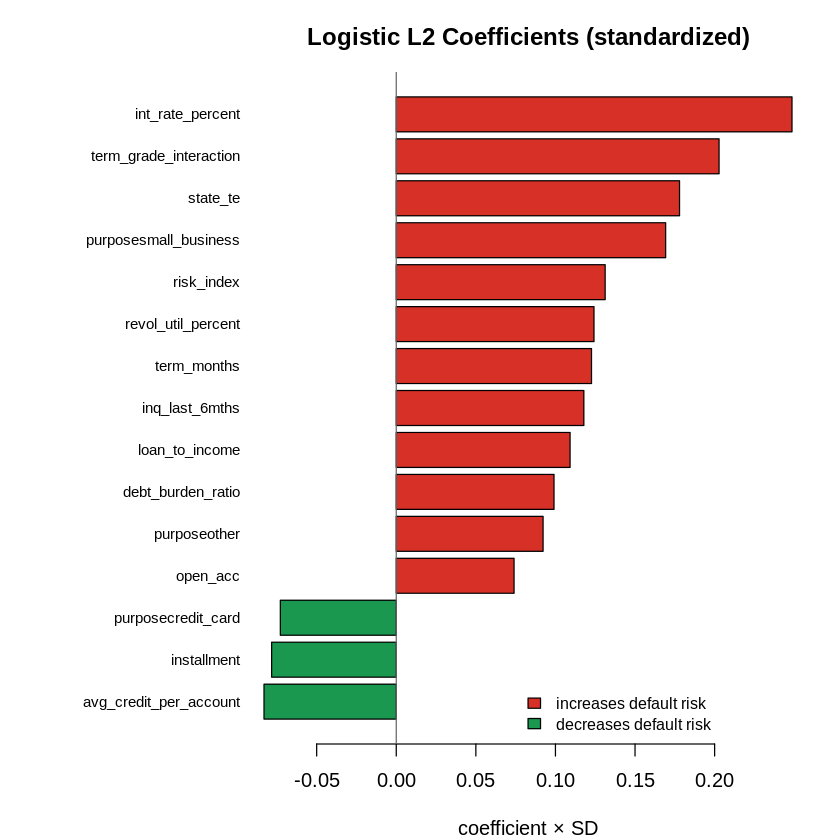

In [ ]:
co <- as.matrix(coef(cv_lr, s = "lambda.min"))
co <- co[rownames(co) != "(Intercept)", , drop = FALSE]

# standardize: coef × feature SD -> puts all features on comparable scale (like SHAP)
feat_sd <- apply(X_tr[, rownames(co)], 2, sd)
co_std  <- co[,1] * feat_sd

ord <- order(-abs(co_std))
tab <- data.frame(feature        = rownames(co)[ord],
                   coefficient    = round(co[ord,1], 4),      # raw log-odds (odds ratio still valid here)
                   odds_ratio     = round(exp(co[ord,1]), 3),
                   std_coefficient = round(co_std[ord], 4),   # use THIS for ranking/plotting
                   direction      = ifelse(co_std[ord] >= 0, "increases default", "decreases default"))
print(head(tab, 15), row.names = FALSE)

top  <- head(tab$feature, 15)
vals <- sort(setNames(co_std, rownames(co))[top])
par(mar = c(4, 11, 3, 2))
barplot(vals, horiz = TRUE, las = 1, cex.names = 0.75,
        col = ifelse(vals >= 0, "#d73027", "#1a9850"),
        main = "Logistic L2 Coefficients (standardized)", xlab = "coefficient × SD")
abline(v = 0, col = "grey40")
legend("bottomright", fill = c("#d73027","#1a9850"),
       legend = c("increases default risk","decreases default risk"), bty = "n", cex = 0.8)

2. XGBOOST

In [ ]:
dtrain <- xgb.DMatrix(X_tr, label=y_tr); dtest <- xgb.DMatrix(X_te, label=y_te)
set.seed(42)
xgb_base <- xgb.train(list(objective="binary:logistic", eval_metric="auc",
  max_depth=4, eta=0.05, subsample=0.8, colsample_bytree=0.8,
  min_child_weight=5, lambda=1, scale_pos_weight=spw, nthread=2),
  dtrain, nrounds=500, verbose=0)
cat(sprintf("XGB baseline test AUC: %.4f\n", auc_score(y_te, predict(xgb_base, dtest))))

XGB baseline test AUC: 0.7094


HYPERPARAMETER TUNING FOR XGBOOST

In [ ]:
grid <- expand.grid(max_depth=c(3,4,5), eta=c(0.03,0.05),
                    subsample=c(0.8,1.0), colsample_bytree=c(0.8,1.0))
xgb_best <- list(auc=0); set.seed(42)
for (i in seq_len(nrow(grid))) {
  p <- list(objective="binary:logistic", eval_metric="auc",
            max_depth=grid$max_depth[i], eta=grid$eta[i], subsample=grid$subsample[i],
            colsample_bytree=grid$colsample_bytree[i], min_child_weight=5,
            lambda=1, scale_pos_weight=spw, nthread=2)
  cvm <- xgb.cv(params=p, data=dtrain, nrounds=800, nfold=3, early_stopping_rounds=40, verbose=0, prediction=FALSE)
  a <- max(cvm$evaluation_log$test_auc_mean)
  if (a > xgb_best$auc) {
    best_nrounds <- if (!is.null(cvm$best_iteration)) cvm$best_iteration else which.max(cvm$evaluation_log$test_auc_mean)
    xgb_best <- list(auc=a, params=p, nrounds=best_nrounds)
  }
}
cat(sprintf("XGB best CV-AUC %.4f (nrounds=%d)\n", xgb_best$auc, xgb_best$nrounds))
set.seed(42)
xgb_model <- xgb.train(xgb_best$params, dtrain, nrounds=xgb_best$nrounds, verbose=0)
p_tr_xgb <- predict(xgb_model, dtrain); p_te_xgb <- predict(xgb_model, dtest)
cat(sprintf("XGB tuned test AUC: %.4f\n", auc_score(y_te, p_te_xgb)))

XGB best CV-AUC 0.7169 (nrounds=201)
XGB tuned test AUC: 0.7127


THRESHOLD TUNING FOR XGBOOST

In [ ]:
thr_xgb <- get_best_threshold(y_tr, p_tr_xgb)
results_all[["xgb"]] <- evaluate_model(y_te, p_te_xgb, thr_xgb, "XGBoost (spw)")
print(results_all[["xgb"]])

          Model    AUC Sensitivity Specificity Precision     F1  Kappa
1 XGBoost (spw) 0.7127      0.4485      0.8238    0.3031 0.3617 0.2272
  Threshold
1      0.59


SHAP FOR XGBOOST

Warning message in cor(X_tr[, f], shap[, f]):
“the standard deviation is zero”
Warning message in cor(X_tr[, f], shap[, f]):
“the standard deviation is zero”
Warning message in cor(X_tr[, f], shap[, f]):
“the standard deviation is zero”
Warning message in cor(X_tr[, f], shap[, f]):
“the standard deviation is zero”


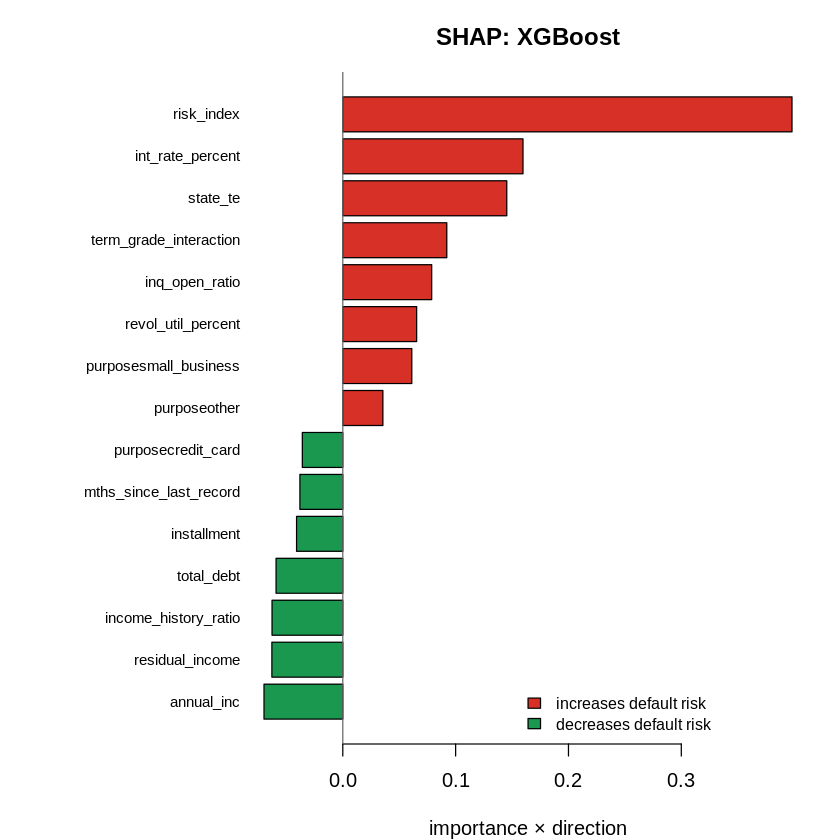

In [ ]:
shap <- predict(xgb_model, X_tr, predcontrib = TRUE)
shap <- shap[, intersect(colnames(shap), colnames(X_tr))]
feats <- colnames(shap)

imp <- colMeans(abs(shap))
dir <- sapply(feats, function(f) if (sd(X_tr[,f])==0) 0 else cor(X_tr[,f], shap[,f]))
signed_imp <- imp * sign(dir)

top <- names(sort(imp, decreasing = TRUE))[1:15]
vals <- sort(signed_imp[top])

par(mar = c(4, 11, 3, 2))
barplot(vals, horiz = TRUE, las = 1, cex.names = 0.75,
        col = ifelse(vals >= 0, "#d73027", "#1a9850"),
        main = "SHAP: XGBoost", xlab = "importance × direction")
abline(v = 0, col = "grey40")
legend("bottomright", fill = c("#d73027","#1a9850"),
       legend = c("increases default risk","decreases default risk"), bty = "n", cex = 0.8)

3. LIGHTGBM

In [ ]:
dtrain_lgb <- lgb.Dataset(X_tr, label=y_tr)

set.seed(42)
lgb_base <- lgb.train(list(objective="binary", metric="auc", num_leaves=31,
  learning_rate=0.05, scale_pos_weight=spw, verbosity=-1),
  dtrain_lgb, nrounds=500, verbose=-1)
cat(sprintf("LGB baseline test AUC: %.4f\n", auc_score(y_te, predict(lgb_base, X_te))))

LGB baseline test AUC: 0.6945


HYPERPARAMETER TUNING FOR LIGHTGBM

In [ ]:
grid <- expand.grid(num_leaves=c(15,31,63), learning_rate=c(0.03,0.05),
                    feature_fraction=c(0.8,1.0))
lgb_best <- list(auc=0); set.seed(42)
for (i in seq_len(nrow(grid))) {
  p <- list(objective="binary", metric="auc", num_leaves=grid$num_leaves[i],
            learning_rate=grid$learning_rate[i], feature_fraction=grid$feature_fraction[i],
            bagging_fraction=0.8, bagging_freq=1, scale_pos_weight=spw, verbosity=-1)
  cvm <- lgb.cv(p, dtrain_lgb, nrounds=800, nfold=3, early_stopping_rounds=40, verbose=-1)
  if (cvm$best_score > lgb_best$auc)
    lgb_best <- list(auc=cvm$best_score, params=p, nrounds=cvm$best_iter)
}
cat(sprintf("LGB best CV-AUC %.4f (nrounds=%d)\n", lgb_best$auc, lgb_best$nrounds))
set.seed(42)
lgb_model <- lgb.train(lgb_best$params, dtrain_lgb, nrounds=lgb_best$nrounds, verbose=-1)
p_tr_lgb <- predict(lgb_model, X_tr); p_te_lgb <- predict(lgb_model, X_te)
cat(sprintf("LGB tuned test AUC: %.4f\n", auc_score(y_te, p_te_lgb)))


LGB best CV-AUC 0.7156 (nrounds=210)
LGB tuned test AUC: 0.7124


THRESHOLD TUNING FOR LIGHTGBM

In [ ]:
thr_lgb <- get_best_threshold(y_tr, p_tr_lgb)
results_all[["lgb"]] <- evaluate_model(y_te, p_te_lgb, thr_lgb, "LightGBM (spw)")
print(results_all[["lgb"]])

           Model    AUC Sensitivity Specificity Precision     F1  Kappa
1 LightGBM (spw) 0.7124      0.4956      0.7863    0.2838 0.3609 0.2153
  Threshold
1      0.58


SHAP FOR LIGHTGBM

Warning message in cor(X_tr[, f], shap_lgb[, f]):
“the standard deviation is zero”
Warning message in cor(X_tr[, f], shap_lgb[, f]):
“the standard deviation is zero”
Warning message in cor(X_tr[, f], shap_lgb[, f]):
“the standard deviation is zero”


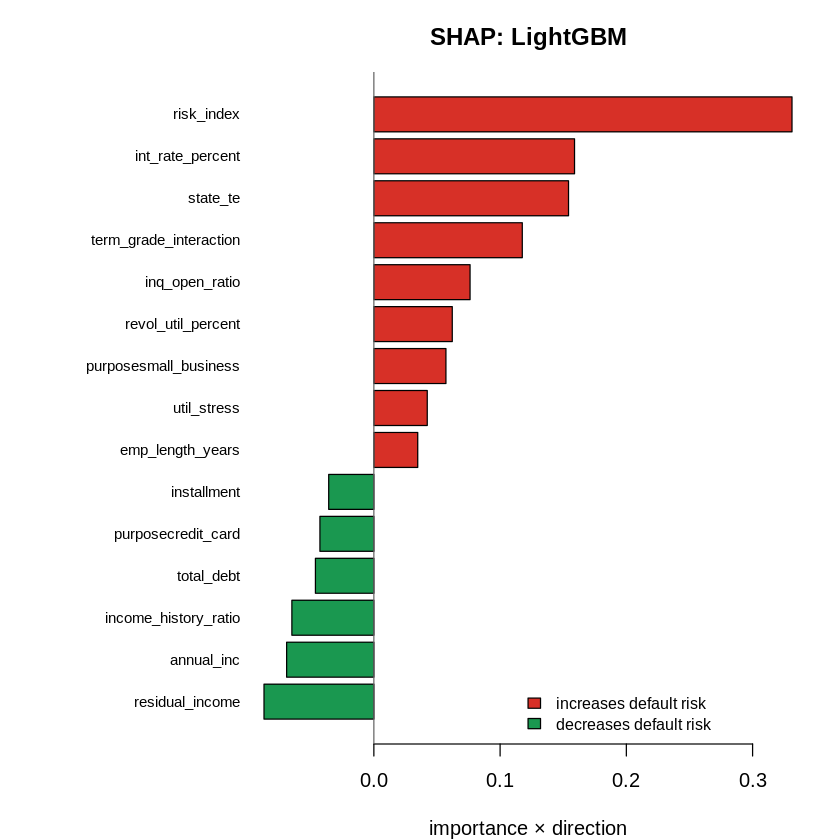

In [ ]:
shap_lgb <- predict(lgb_model, X_tr, type = "contrib")
shap_lgb <- shap_lgb[, -ncol(shap_lgb)]
colnames(shap_lgb) <- colnames(X_tr)
feats <- colnames(shap_lgb)

imp <- colMeans(abs(shap_lgb))
dir <- sapply(feats, function(f) if (sd(X_tr[,f])==0) 0 else cor(X_tr[,f], shap_lgb[,f]))
signed_imp <- imp * sign(dir)

top  <- names(sort(imp, decreasing = TRUE))[1:15]
vals <- sort(signed_imp[top])

par(mar = c(4, 11, 3, 2))
barplot(vals, horiz = TRUE, las = 1, cex.names = 0.75,
        col = ifelse(vals >= 0, "#d73027", "#1a9850"),
        main = "SHAP: LightGBM", xlab = "importance × direction")
abline(v = 0, col = "grey40")
legend("bottomright", fill = c("#d73027","#1a9850"),
       legend = c("increases default risk","decreases default risk"), bty = "n", cex = 0.8)

ENSEMBLE: STACKING OF THE THREE MODELS

In [ ]:
set.seed(42)
K <- 5
folds <- sample(rep(1:K, length.out = nrow(X_tr)))
oof      <- matrix(0, nrow(X_tr), 3); colnames(oof) <- c("lr","xgb","lgb")
test_acc <- matrix(0, nrow(X_te), 3); colnames(test_acc) <- c("lr","xgb","lgb")

for (f in 1:K) {
  tr <- which(folds != f); va <- which(folds == f)

  m_lr  <- glmnet(X_tr[tr,], y_tr[tr], family="binomial", alpha=0,
                  lambda=cv_lr$lambda.min, weights=wts[tr])
  oof[va,"lr"]     <- as.numeric(predict(m_lr, X_tr[va,], type="response"))
  test_acc[,"lr"]  <- test_acc[,"lr"]  + as.numeric(predict(m_lr, X_te, type="response"))/K

  m_xgb <- xgb.train(xgb_best$params, xgb.DMatrix(X_tr[tr,], label=y_tr[tr]),
                     nrounds=xgb_best$nrounds, verbose=0)
  oof[va,"xgb"]    <- predict(m_xgb, xgb.DMatrix(X_tr[va,]))
  test_acc[,"xgb"] <- test_acc[,"xgb"] + predict(m_xgb, xgb.DMatrix(X_te))/K

  m_lgb <- lgb.train(lgb_best$params, lgb.Dataset(X_tr[tr,], label=y_tr[tr]),
                     nrounds=lgb_best$nrounds, verbose=-1)
  oof[va,"lgb"]    <- predict(m_lgb, X_tr[va,])
  test_acc[,"lgb"] <- test_acc[,"lgb"] + predict(m_lgb, X_te)/K
}

meta <- glm(y_tr ~ ., data = data.frame(y_tr=y_tr, oof), family = binomial)

p_te_stack <- predict(meta, as.data.frame(test_acc), type="response")
p_tr_stack <- predict(meta, as.data.frame(oof),      type="response")

# F1-tuned threshold — same get_best_threshold used by the base models
thr_stack <- get_best_threshold(y_tr, p_tr_stack)

results_all[["stack"]] <- evaluate_model(y_te, p_te_stack, thr_stack, "Stacking (LR+XGB+LGB)")
print(results_all[["stack"]])

final_table <- do.call(rbind, results_all)
print(final_table, row.names = FALSE)

                  Model   AUC Sensitivity Specificity Precision     F1  Kappa
1 Stacking (LR+XGB+LGB) 0.716       0.556      0.7416    0.2688 0.3624 0.2062
  Threshold
1      0.18
                 Model    AUC Sensitivity Specificity Precision     F1  Kappa
     Logistic L2 (spw) 0.7133      0.6243      0.6812    0.2507 0.3578 0.1888
         XGBoost (spw) 0.7127      0.4485      0.8238    0.3031 0.3617 0.2272
        LightGBM (spw) 0.7124      0.4956      0.7863    0.2838 0.3609 0.2153
 Stacking (LR+XGB+LGB) 0.7160      0.5560      0.7416    0.2688 0.3624 0.2062
 Threshold
      0.51
      0.59
      0.58
      0.18


ROC + PR CURVES

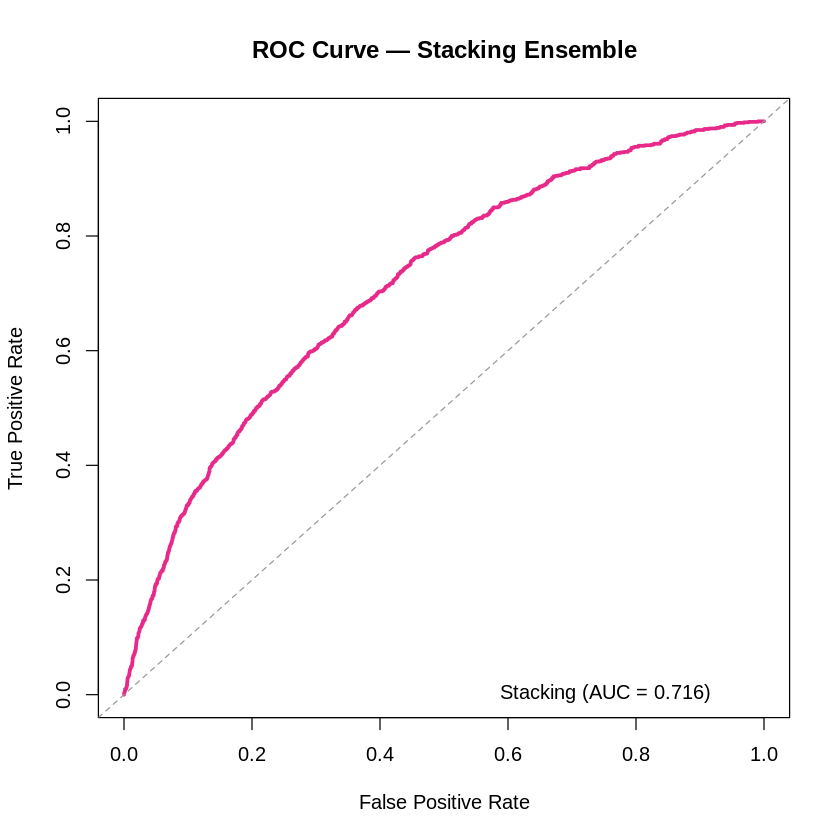

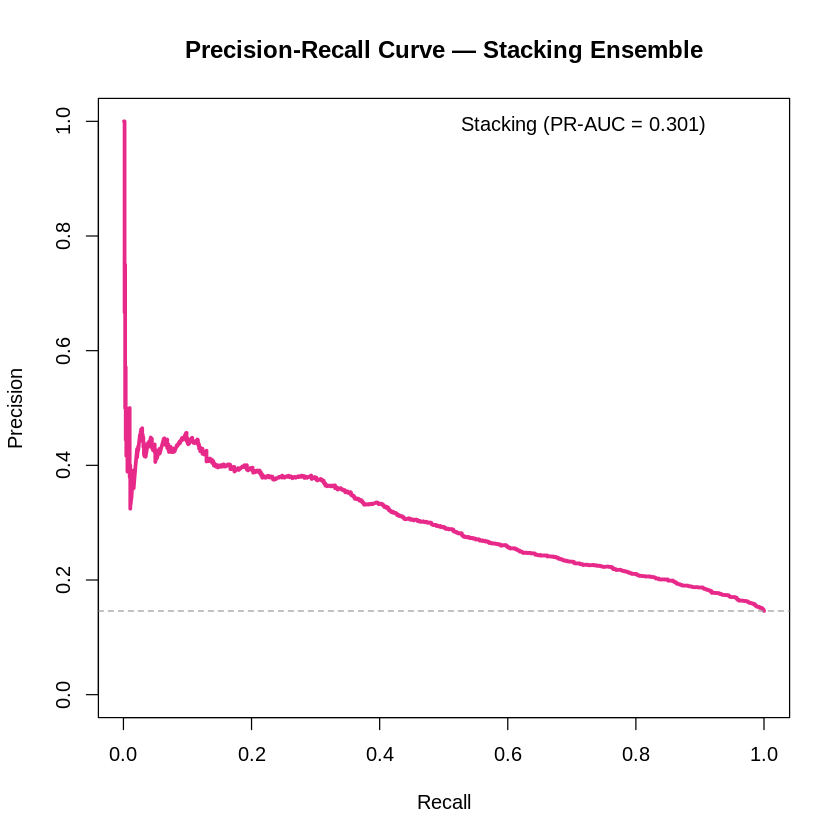

In [ ]:
p <- p_te_stack
ord <- order(p, decreasing = TRUE); y <- y_te[ord]
tpr <- c(0, cumsum(y==1)/sum(y_te==1))
fpr <- c(0, cumsum(y==0)/sum(y_te==0))
plot(fpr, tpr, type="l", col="#e7298a", lwd=3,
     xlab="False Positive Rate", ylab="True Positive Rate",
     main="ROC Curve — Stacking Ensemble")
abline(0, 1, lty=2, col="grey60")
legend("bottomright", bty="n",
       legend=sprintf("Stacking (AUC = %.3f)", auc_score(y_te, p)))

tp <- cumsum(y==1); fp <- cumsum(y==0)
recall <- tp/sum(y_te==1); precision <- tp/(tp+fp)
pr_auc <- sum(diff(c(0, recall)) * precision)
plot(recall, precision, type="l", col="#e7298a", lwd=3,
     xlab="Recall", ylab="Precision", ylim=c(0,1),
     main="Precision-Recall Curve — Stacking Ensemble")
abline(h=mean(y_te), lty=2, col="grey60")
legend("topright", bty="n",
       legend=sprintf("Stacking (PR-AUC = %.3f)", pr_auc))

SHAP FOR ENSEMBLE


=== Ensemble attribution by base model ===
 base_model contribution_pct
         lr             47.0
        xgb             35.0
        lgb             17.9


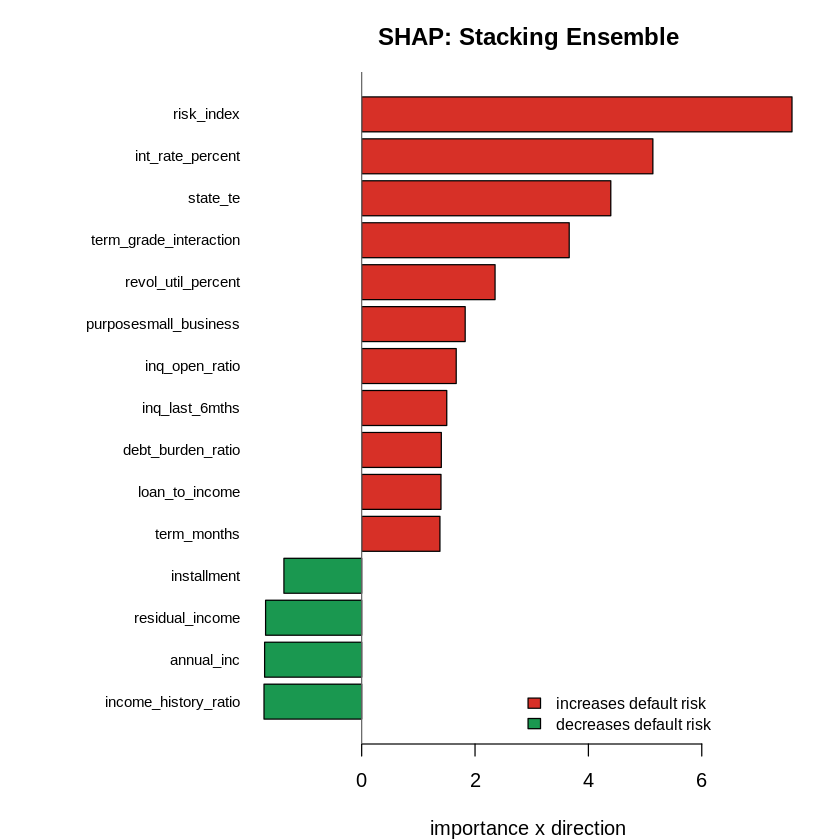

In [ ]:
# IMPORTANCE OF BASE MODEL
co_meta <- coef(meta)[c("lr","xgb","lgb")]
sd_meta <- apply(as.data.frame(test_acc), 2, sd)
contrib <- abs(co_meta * sd_meta)
contrib <- round(100 * contrib / sum(contrib), 1)
cat(" Ensemble attribution by base model")
print(data.frame(base_model = names(contrib), contribution_pct = contrib), row.names = FALSE)

# FEATURE
shap_xgb <- predict(xgb_model, X_te, predcontrib = TRUE)
shap_xgb <- shap_xgb[, intersect(colnames(shap_xgb), colnames(X_te))]

shap_lgb <- predict(lgb_model, X_te, type = "contrib")
shap_lgb <- shap_lgb[, -ncol(shap_lgb)]; colnames(shap_lgb) <- colnames(X_te)
#LOGISTIC REG
co_lr <- as.numeric(coef(cv_lr, s = "lambda.min"))[-1]
names(co_lr) <- rownames(coef(cv_lr, s = "lambda.min"))[-1]
Xc <- scale(X_te, center = TRUE, scale = FALSE)
shap_lr <- sweep(Xc[, names(co_lr)], 2, co_lr, `*`)

# COMMON FEATURE SET
common <- Reduce(intersect, list(colnames(shap_lr), colnames(shap_xgb), colnames(shap_lgb)))
norm <- function(m) m / mean(abs(m))
S_lr  <- norm(shap_lr[,  common])
S_xgb <- norm(shap_xgb[, common])
S_lgb <- norm(shap_lgb[, common])

w <- co_meta * sd_meta; w <- w / sum(w)
shap_ens <- w["lr"]*S_lr + w["xgb"]*S_xgb + w["lgb"]*S_lgb

# TOP 15
imp  <- colMeans(abs(shap_ens))
dir  <- sapply(common, function(f) if (sd(X_te[,f])==0) 0 else cor(X_te[,f], shap_ens[,f]))
top  <- names(sort(imp, decreasing = TRUE))[1:15]
vals <- sort((imp * sign(dir))[top])

par(mar = c(4, 11, 3, 2))
barplot(vals, horiz = TRUE, las = 1, cex.names = 0.75,
        col = ifelse(vals >= 0, "#d73027", "#1a9850"),
        main = "SHAP: Stacking Ensemble", xlab = "importance x direction")
abline(v = 0, col = "grey40")
legend("bottomright", fill = c("#d73027","#1a9850"),
       legend = c("increases default risk","decreases default risk"), bty = "n", cex = 0.8)

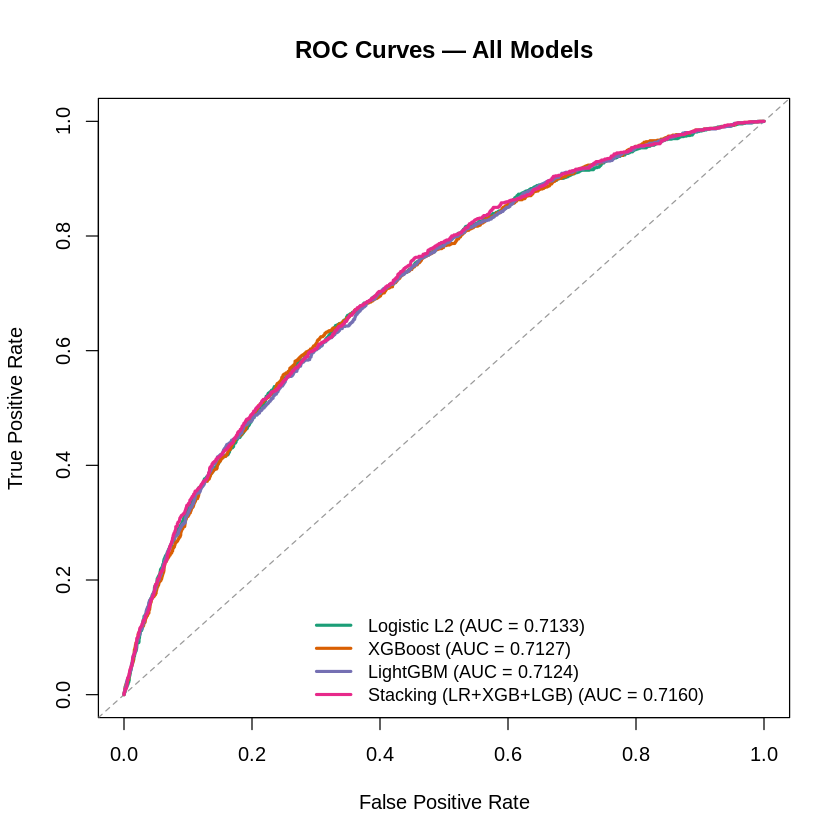

In [ ]:
# all four models' test predictions
roc_preds <- list(
  "Logistic L2"            = p_te_lr,
  "XGBoost"                = p_te_xgb,
  "LightGBM"               = p_te_lgb,
  "Stacking (LR+XGB+LGB)"  = p_te_stack
)
roc_cols <- c("#1b9e77", "#d95f02", "#7570b3", "#e7298a")

plot(0:1, 0:1, type = "n",
     xlab = "False Positive Rate", ylab = "True Positive Rate",
     main = "ROC Curves — All Models")
abline(0, 1, lty = 2, col = "grey60")

# draw each ROC + collect legend text
leg <- character(length(roc_preds))
for (i in seq_along(roc_preds)) {
  p   <- roc_preds[[i]]
  ord <- order(p, decreasing = TRUE); yy <- y_te[ord]
  tpr <- c(0, cumsum(yy == 1) / sum(y_te == 1))
  fpr <- c(0, cumsum(yy == 0) / sum(y_te == 0))
  lines(fpr, tpr, col = roc_cols[i], lwd = 2.5)
  leg[i] <- sprintf("%s (AUC = %.4f)", names(roc_preds)[i], auc_score(y_te, p))
}
legend("bottomright", legend = leg, col = roc_cols, lwd = 2.5, bty = "n", cex = 0.9)

LIFT CHART

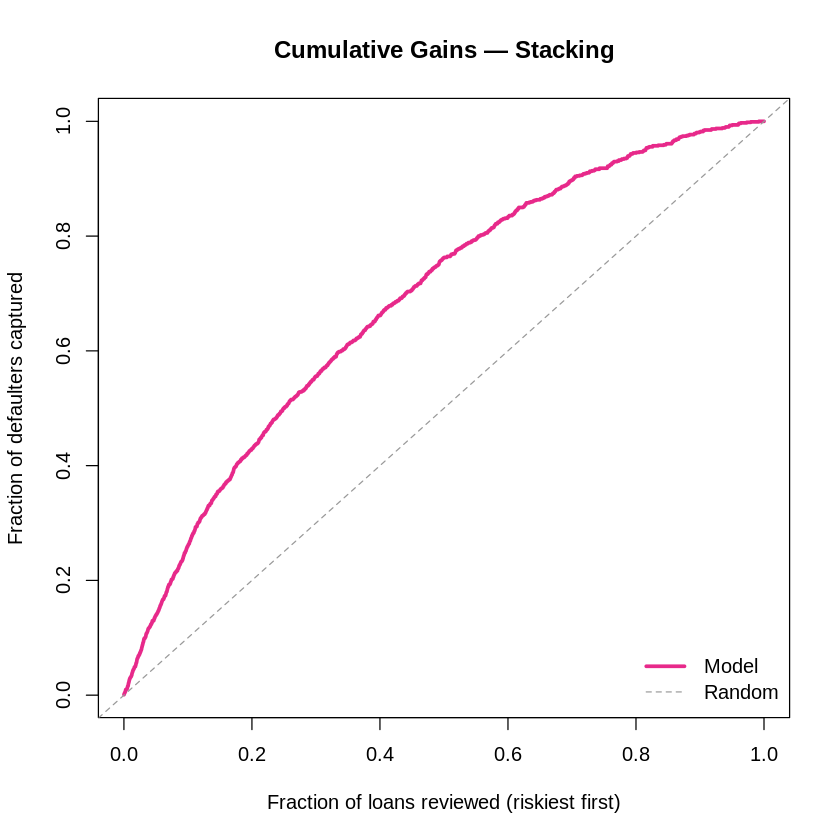

 decile pct_reviewed gains_pct lift
      1           10      26.0 2.82
      2           20      42.9 2.39
      3           30      55.6 1.99
      4           40      66.2 1.75
      5           50      76.2 1.58
      6           60      83.3 1.45
      7           70      89.8 1.33
      8           80      94.5 1.23
      9           90      98.1 1.13
     10          100     100.0 1.05


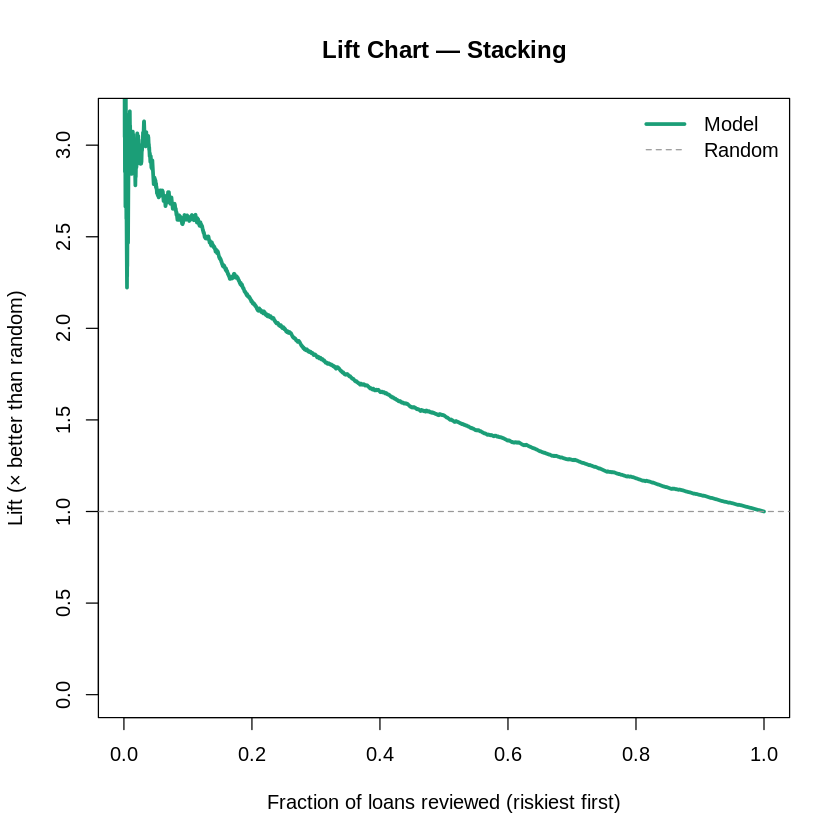

In [ ]:

p <- p_te_stack
ord <- order(p, decreasing = TRUE)
y   <- y_te[ord]
n   <- length(y); total_bad <- sum(y)

pct_pop  <- (1:n) / n
cum_gain <- cumsum(y) / total_bad
lift     <- cum_gain / pct_pop

plot(pct_pop, cum_gain, type="l", col="#e7298a", lwd=3,
     xlab="Fraction of loans reviewed (riskiest first)",
     ylab="Fraction of defaulters captured",
     main="Cumulative Gains — Stacking")
abline(0, 1, lty=2, col="grey60")
legend("bottomright", bty="n", lwd=c(3,1), lty=c(1,2),
       col=c("#e7298a","grey60"), legend=c("Model","Random"))

plot(pct_pop, lift, type="l", col="#1b9e77", lwd=3,
     xlab="Fraction of loans reviewed (riskiest first)",
     ylab="Lift (× better than random)",
     main="Lift Chart — Stacking", ylim=c(0, max(lift[pct_pop>0.01])))
abline(h=1, lty=2, col="grey60")
legend("topright", bty="n", lwd=c(3,1), lty=c(1,2),
       col=c("#1b9e77","grey60"), legend=c("Model","Random"))


deciles <- cut(pct_pop, breaks=seq(0,1,0.1), labels=1:10, include.lowest=TRUE)
lift_tbl <- data.frame(
  decile      = 1:10,
  pct_reviewed= seq(10,100,10),
  gains_pct   = round(tapply(cum_gain, deciles, max)*100, 1),
  lift        = round(tapply(lift, deciles, mean), 2)
)
print(lift_tbl, row.names=FALSE)

This means if we check the 20% of highest-risk loans, our model identifies 44% of all defaulters.

WITH SMOTE

In [ ]:
system("apt-get update && apt-get install -y libglpk-dev")

In [ ]:
install.packages("igraph", type = "source")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
library(smotefamily); library(glmnet); library(xgboost); library(lightgbm)

set.seed(42)
sm   <- SMOTE(X = as.data.frame(X_tr), target = y_tr, K = 5)
X_sm <- as.matrix(sm$data[, colnames(X_tr)])          # keep same column order as X_te
y_sm <- as.integer(as.character(sm$data$class))
cat("Balance — original:", table(y_tr), "| after SMOTE:", table(y_sm), "\n")

results_smote <- list()



Balance — original: 26360 4501 | after SMOTE: 26360 22505 


LOGISTIC REGRESSION USING SMOTE

In [ ]:
set.seed(42)
cv_lr_sm  <- cv.glmnet(X_sm, y_sm, family="binomial", alpha=0, type.measure="auc", nfolds=5)
p_tr_lr_sm <- as.numeric(predict(cv_lr_sm, X_tr, s="lambda.min", type="response"))
p_te_lr_sm <- as.numeric(predict(cv_lr_sm, X_te, s="lambda.min", type="response"))
thr <- get_best_threshold(y_tr, p_tr_lr_sm)
results_smote[["lr"]] <- evaluate_model(y_te, p_te_lr_sm, thr, "Logistic L2 (SMOTE)")
print(results_smote[["lr"]])


                Model    AUC Sensitivity Specificity Precision     F1  Kappa
1 Logistic L2 (SMOTE) 0.7115      0.5968      0.7014    0.2545 0.3569 0.1915
  Threshold
1      0.49


XGBOOST USING SMOTE

In [ ]:
xgb_p_sm <- xgb_best$params; xgb_p_sm$scale_pos_weight <- 1
set.seed(42)
xgb_sm <- xgb.train(xgb_p_sm, xgb.DMatrix(X_sm, label=y_sm), nrounds=xgb_best$nrounds, verbose=0)
p_tr_xgb_sm <- predict(xgb_sm, xgb.DMatrix(X_tr)); p_te_xgb_sm <- predict(xgb_sm, xgb.DMatrix(X_te))
thr <- get_best_threshold(y_tr, p_tr_xgb_sm)
results_smote[["xgb"]] <- evaluate_model(y_te, p_te_xgb_sm, thr, "XGBoost (SMOTE)")
print(results_smote[["xgb"]])


            Model    AUC Sensitivity Specificity Precision     F1  Kappa
1 XGBoost (SMOTE) 0.6992       0.556      0.7202    0.2534 0.3482 0.1847
  Threshold
1      0.26


LIGHTGBM USING SMOTE

In [ ]:
lgb_p_sm <- lgb_best$params; lgb_p_sm$scale_pos_weight <- 1
set.seed(42)
lgb_sm <- lgb.train(lgb_p_sm, lgb.Dataset(X_sm, label=y_sm), nrounds=lgb_best$nrounds, verbose=-1)
p_tr_lgb_sm <- predict(lgb_sm, X_tr); p_te_lgb_sm <- predict(lgb_sm, X_te)
thr <- get_best_threshold(y_tr, p_tr_lgb_sm)
results_smote[["lgb"]] <- evaluate_model(y_te, p_te_lgb_sm, thr, "LightGBM (SMOTE)")
print(results_smote[["lgb"]])



             Model    AUC Sensitivity Specificity Precision     F1  Kappa
1 LightGBM (SMOTE) 0.7025      0.5284      0.7502    0.2655 0.3534 0.1975
  Threshold
1      0.24


In [ ]:
smote_table <- do.call(rbind, results_smote)
print(smote_table, row.names = FALSE)

               Model    AUC Sensitivity Specificity Precision     F1  Kappa
 Logistic L2 (SMOTE) 0.7115      0.5968      0.7014    0.2545 0.3569 0.1915
     XGBoost (SMOTE) 0.6992      0.5560      0.7202    0.2534 0.3482 0.1847
    LightGBM (SMOTE) 0.7025      0.5284      0.7502    0.2655 0.3534 0.1975
 Threshold
      0.49
      0.26
      0.24


SMOTE ROC AND PR

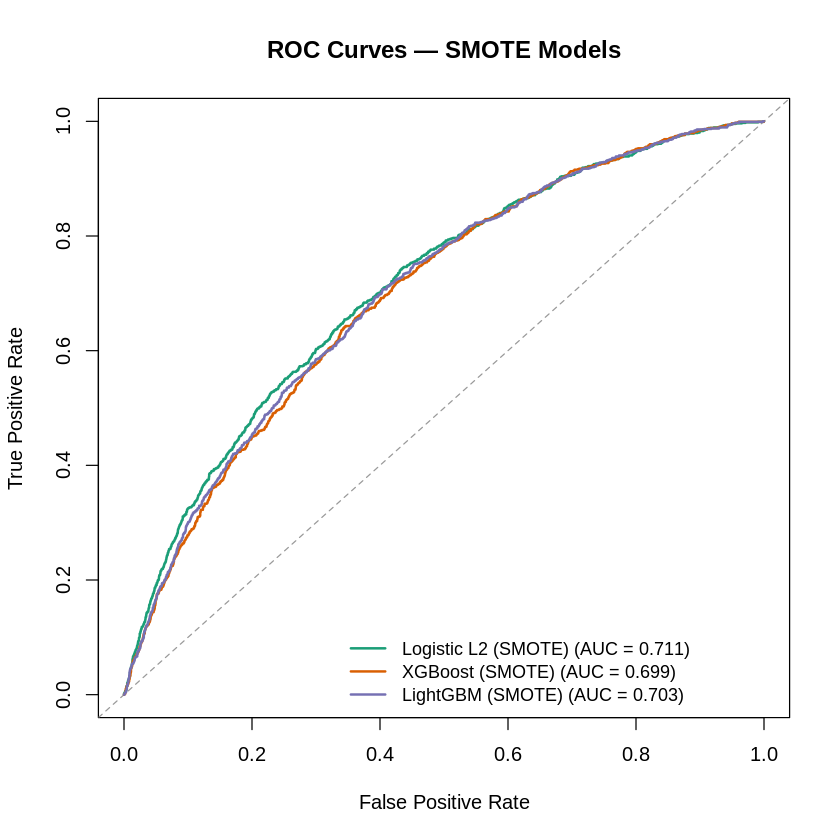

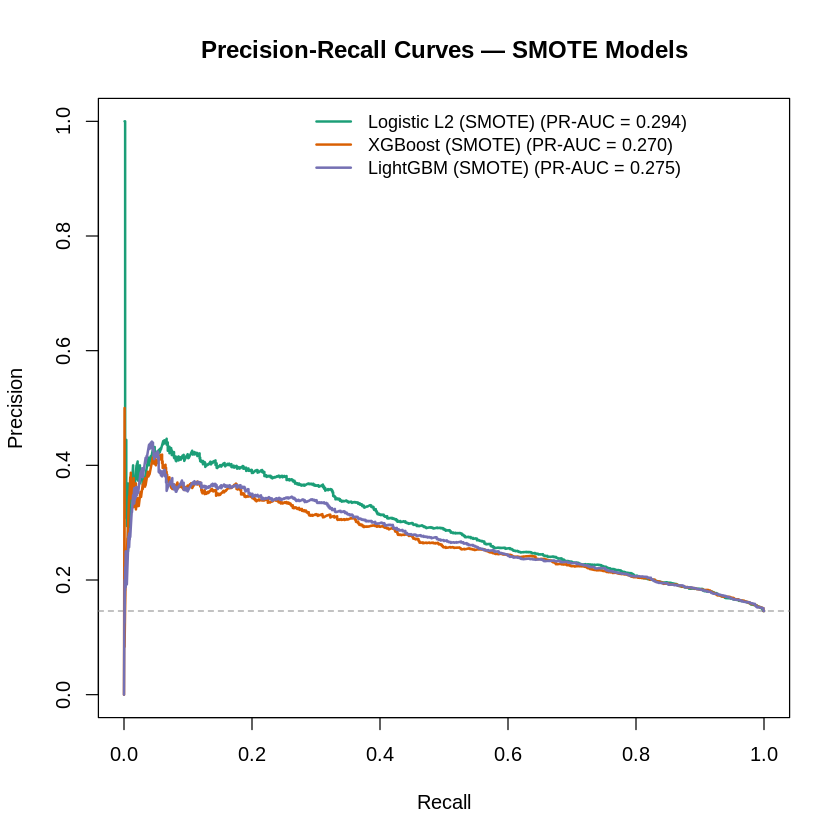

In [ ]:
sm_preds <- list("Logistic L2 (SMOTE)" = p_te_lr_sm,
                 "XGBoost (SMOTE)"     = p_te_xgb_sm,
                 "LightGBM (SMOTE)"    = p_te_lgb_sm)
sm_cols  <- c("#1b9e77", "#d95f02", "#7570b3")

# --- ROC ---
plot(0:1, 0:1, type="n", xlab="False Positive Rate", ylab="True Positive Rate",
     main="ROC Curves — SMOTE Models")
abline(0, 1, lty=2, col="grey60")
leg <- character()
for (i in seq_along(sm_preds)) {
  p <- sm_preds[[i]]; ord <- order(p, decreasing=TRUE); y <- y_te[ord]
  tpr <- c(0, cumsum(y==1)/sum(y_te==1)); fpr <- c(0, cumsum(y==0)/sum(y_te==0))
  lines(fpr, tpr, col=sm_cols[i], lwd=2)
  leg[i] <- sprintf("%s (AUC = %.3f)", names(sm_preds)[i], auc_score(y_te, p))
}
legend("bottomright", legend=leg, col=sm_cols, lwd=2, cex=0.9, bty="n")

# --- Precision-Recall ---
plot(0:1, 0:1, type="n", xlab="Recall", ylab="Precision", ylim=c(0,1),
     main="Precision-Recall Curves — SMOTE Models")
abline(h=mean(y_te), lty=2, col="grey60")
leg <- character()
for (i in seq_along(sm_preds)) {
  p <- sm_preds[[i]]; ord <- order(p, decreasing=TRUE); y <- y_te[ord]
  tp <- cumsum(y==1); fp <- cumsum(y==0)
  recall <- tp/sum(y_te==1); precision <- tp/(tp+fp)
  lines(recall, precision, col=sm_cols[i], lwd=2)
  leg[i] <- sprintf("%s (PR-AUC = %.3f)", names(sm_preds)[i], sum(diff(c(0,recall))*precision))
}
legend("topright", legend=leg, col=sm_cols, lwd=2, cex=0.9, bty="n")

EFFECT OF LEAKAGE COLUMNS

THIS IS EVERYTHING DONE ABOVE

In [ ]:
build_pipeline <- function(keep_leak = character(0)) {   # pass which leakage cols to KEEP
  ld <- read.csv("/content/loan_data_cleaned.csv")
  ld <- ld %>% select(-collections_12_mths_ex_med)
  ld <- ld %>% filter(loan_status != "Current") %>%
    mutate(target = ifelse(loan_status == "Charged Off", 1, 0))

  # always drop (non-leakage redundant + text dates) — identical to your main pipeline
  ld <- ld %>% select(-any_of(c("id","member_id","loan_status","issue_d","earliest_cr_line",
        "zip_code","grade","funded_amnt","funded_amnt_inv","issue_year","last_pymnt_d","last_credit_pull_d")))

  # keep only the leakage columns requested; drop the rest
  all_leak <- c("out_prncp","out_prncp_inv","total_pymnt","total_pymnt_inv","total_rec_prncp",
                "total_rec_int","total_rec_late_fee","recoveries","collection_recovery_fee","last_pymnt_amnt")
  ld <- ld %>% select(-any_of(setdiff(all_leak, keep_leak)))

  # ordinal encode sub_grade
  sub_levels <- as.vector(t(outer(LETTERS[1:7], 1:5, paste0)))
  ld$sub_grade_numeric <- match(ld$sub_grade, sub_levels)
  ld <- ld %>% select(-sub_grade)

  # feature engineering
  ld <- ld %>% mutate(
    inq_open_ratio = inq_last_6mths/(open_acc+1),
    loan_to_income = loan_amnt/annual_inc,
    debt_service_ratio = (installment + (dti/100*annual_inc/12))/(annual_inc/12),
    residual_income = (annual_inc/12) - installment - (dti/100*annual_inc/12),
    total_debt = dti*annual_inc/100,
    dti_squared = dti^2,
    term_grade_interaction = term_months*sub_grade_numeric,
    grade_dti_risk = sub_grade_numeric*(dti/100),
    income_history_score = (annual_inc/10000)*(credit_history_months/12),
    income_history_ratio = annual_inc/(credit_history_months+1),
    util_stress = revol_util_percent*(delinq_2yrs+1),
    high_util_flag = as.integer(revol_util_percent>80),
    recent_stress = as.integer(inq_last_6mths>2) + as.integer(delinq_2yrs>0) +
                    as.integer(mths_since_last_delinq<12 & !is.na(mths_since_last_delinq)) +
                    as.integer(revol_util_percent>80),
    risk_index = (sub_grade_numeric/35)*0.25 + (inq_open_ratio/2)*0.20 + (dti/40)*0.15 +
                 (loan_to_income)*0.15 + as.numeric(term_months==60)*0.15 + (delinq_2yrs/5)*0.10)

  # log-transform skewed, non-negative continuous columns
  excl <- c("target","sub_grade_numeric","term_months","high_util_flag","recent_stress",
            "never_delinq","pub_rec_bankruptcies_binary","has_public_record",
            "mths_since_last_delinq","mths_since_last_record")
  num_df <- ld %>% select(where(is.numeric))
  cc <- setdiff(names(num_df)[sapply(num_df, function(x) length(unique(na.omit(x)))>20)], excl)
  sk <- sapply(cc, function(col) skewness(ld[[col]], na.rm=TRUE))
  mn <- sapply(cc, function(col) min(ld[[col]], na.rm=TRUE))
  for (col in cc[sk>0.75 & mn>=0]) ld[[col]] <- log1p(ld[[col]])

  # stratified 80/20 split
  set.seed(42)
  ld$.row <- seq_len(nrow(ld))
  tr_idx <- ld %>% group_by(target) %>% slice_sample(prop=0.8) %>% pull(.row)
  trn <- ld %>% filter(.row %in% tr_idx)  %>% select(-.row)
  tst <- ld %>% filter(!(.row %in% tr_idx)) %>% select(-.row)

  # z-score scaling (train params applied to test)
  ncs <- setdiff(names(trn)[sapply(trn, is.numeric)], "target")
  mu  <- sapply(trn[ncs], mean, na.rm=TRUE)
  sdv <- sapply(trn[ncs], sd,   na.rm=TRUE); sdv[sdv==0] <- 1
  trn[ncs] <- scale(trn[ncs], center=mu, scale=sdv)
  tst[ncs] <- scale(tst[ncs], center=mu, scale=sdv)

  # state target-encoding (train only, smoothed)
  gl <- mean(trn$target); k <- 50
  sm <- trn %>% group_by(addr_state) %>%
    summarise(m=mean(target), n=n(), .groups="drop") %>%
    mutate(state_te=(m*n+gl*k)/(n+k)) %>% select(addr_state, state_te)
  trn <- trn %>% left_join(sm, by="addr_state") %>% select(-addr_state)
  tst <- tst %>% left_join(sm, by="addr_state") %>%
    mutate(state_te=ifelse(is.na(state_te), gl, state_te)) %>% select(-addr_state)

  # one-hot encode remaining categoricals, align test to train columns
  cats <- intersect(c("home_ownership","verification_status","purpose"), names(trn))
  dummify <- function(df, cols) {
    df[cols] <- lapply(df[cols], as.factor)
    mm <- model.matrix(~ . -1, data=df[cols])
    cbind(df[setdiff(names(df), cols)], as.data.frame(mm))
  }
  trn <- dummify(trn, cats); tst <- dummify(tst, cats)
  for (mcol in setdiff(names(trn), names(tst))) tst[[mcol]] <- 0
  tst <- tst[, names(trn)]

  list(train = trn, test = tst)
}

In [ ]:
leak_levels <- list(
  "0 - Honest (no leakage)" = character(0),
  "1 leakage column"        = c("last_pymnt_amnt"),
  "2 leakage columns"       = c("last_pymnt_amnt","total_rec_int"),
  "4 leakage columns"       = c("last_pymnt_amnt","total_rec_int","total_rec_late_fee","out_prncp"),
  "ALL leakage columns"     = c("out_prncp","out_prncp_inv","total_pymnt","total_pymnt_inv",
                                "total_rec_prncp","total_rec_int","total_rec_late_fee",
                                "recoveries","collection_recovery_fee","last_pymnt_amnt")
)


leak_preds <- list()

leak_results <- do.call(rbind, lapply(names(leak_levels), function(lbl) {
  dat <- build_pipeline(leak_levels[[lbl]])
  trn <- dat$train; tst <- dat$test
  yt <- trn$target; ye <- tst$target
  w  <- ifelse(yt==1, sum(yt==0)/sum(yt==1), 1)
  m  <- glm(target ~ ., data=trn, family=binomial, weights=w)
  p_tr <- predict(m, trn, type="response"); p_te <- predict(m, tst, type="response")
  leak_preds[[lbl]] <<- list(p = p_te, y = ye)
  evaluate_model(ye, p_te, get_best_threshold(yt, p_tr), lbl)
}))

print(leak_results, row.names = FALSE)

Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”
Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”
Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”
Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”
Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”
Warning message:
“glm.fit: algorithm did not converge”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


                   Model    AUC Sensitivity Specificity Precision     F1  Kappa
 0 - Honest (no leakage) 0.7110      0.5302      0.7645    0.2778 0.3646 0.2141
        1 leakage column 0.8658      0.7087      0.8281    0.4133 0.5221 0.4141
       2 leakage columns 0.9117      0.7291      0.9068    0.5721 0.6412 0.5710
       4 leakage columns 0.9160      0.7549      0.8995    0.5622 0.6444 0.5730
     ALL leakage columns 0.9990      0.9964      0.9997    0.9982 0.9973 0.9969
 Threshold
      0.57
      0.58
      0.61
      0.58
      0.05


ROC AND LIFT CHART

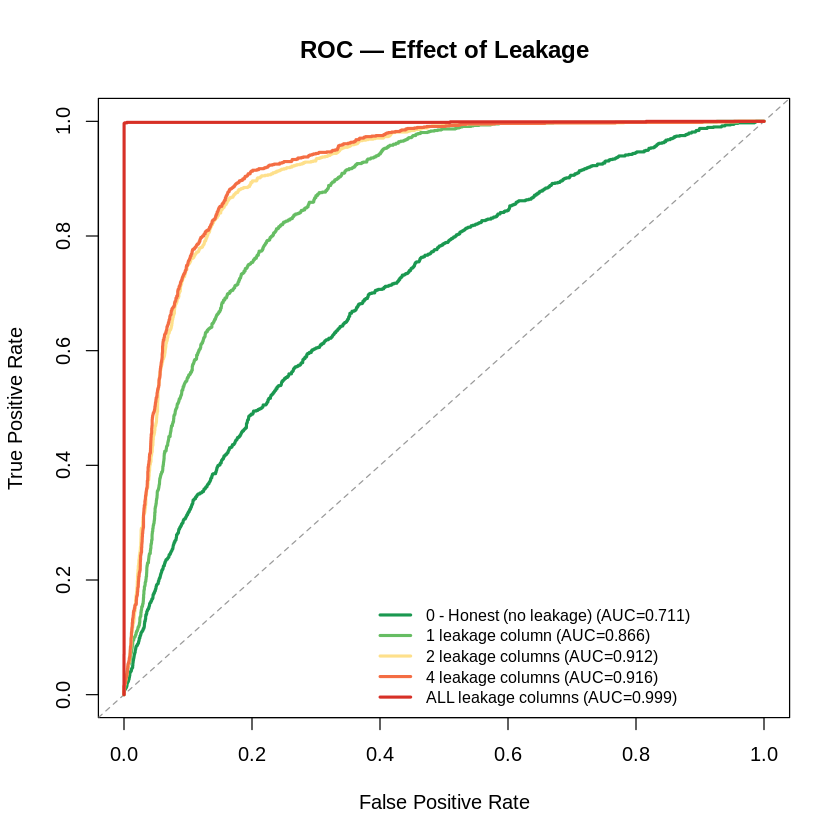

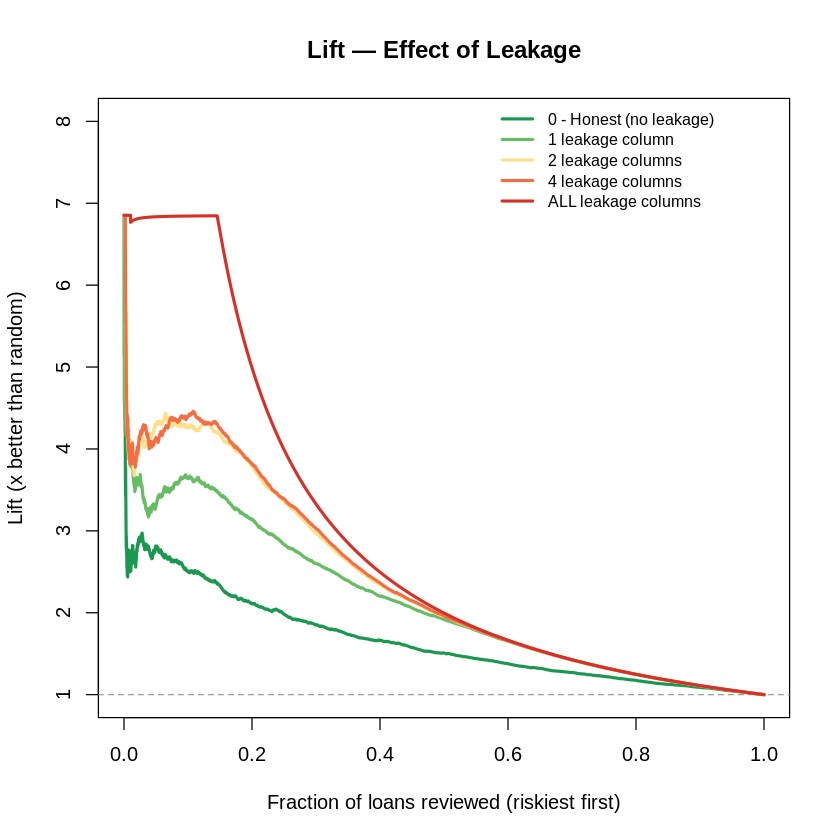

In [ ]:
cols <- c("#1a9850", "#66bd63", "#fee08b", "#f46d43", "#d73027")
plot(0:1, 0:1, type="n", xlab="False Positive Rate", ylab="True Positive Rate",
     main="ROC — Effect of Leakage")
abline(0,1,lty=2,col="grey60"); leg <- character()
for (i in seq_along(leak_preds)) {
  p <- leak_preds[[i]]$p; y0 <- leak_preds[[i]]$y
  o <- order(p, decreasing=TRUE); yy <- y0[o]
  tpr <- c(0, cumsum(yy==1)/sum(y0==1)); fpr <- c(0, cumsum(yy==0)/sum(y0==0))
  lines(fpr, tpr, col=cols[i], lwd=2.5)
  leg[i] <- sprintf("%s (AUC=%.3f)", names(leak_preds)[i], auc_score(y0, p))
}
legend("bottomright", legend=leg, col=cols, lwd=2.5, cex=0.8, bty="n")

plot(NA, xlim=c(0,1), ylim=c(1,8), xlab="Fraction of loans reviewed (riskiest first)",
     ylab="Lift (x better than random)", main="Lift — Effect of Leakage")
abline(h=1, lty=2, col="grey60"); leg <- character()
for (i in seq_along(leak_preds)) {
  p <- leak_preds[[i]]$p; y0 <- leak_preds[[i]]$y
  o <- order(p, decreasing=TRUE); yy <- y0[o]
  pct <- (seq_along(yy))/length(yy); lift <- (cumsum(yy)/sum(y0==1))/pct
  lines(pct, lift, col=cols[i], lwd=2.5)
  leg[i] <- names(leak_preds)[i]
}
legend("topright", legend=leg, col=cols, lwd=2.5, cex=0.8, bty="n")

TIME-SERIES FORECASTING: COMPARING CANDIDATE MODELS BY 12-MONTH BACKTEST MAPE, SELECTING THE BEST, REFITTING ON FULLSERIES TO FORECAST 12 MONTHS

For forecasting, as we need date, we will load loan_data_cleaned.csv.

In [ ]:
install.packages("forecast")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
 loan_data <- read.csv("/content/loan_data_cleaned.csv")
 dim(loan_data)

[1] 39717    51

In [ ]:
library(forecast); library(dplyr); library(lubridate); library(ggplot2)

#MONTHLY VOLUME SERIES
raw <- read.csv("/content/loan_data_cleaned.csv")
raw$issue_d <- as.Date(raw$issue_d)                       # format: "2011-12-01"

monthly <- raw %>%
  mutate(month = floor_date(issue_d, "month")) %>%
  count(month, name = "volume") %>%
  arrange(month)

y <- ts(monthly$volume, start = c(2007, 6), frequency = 12)

# CANDIDATE MODELS
H <- 12                                                 # forecast horizon
train <- head(y, length(y) - H)
test  <- tail(y, H)
mape  <- function(actual, pred) mean(abs((actual - pred) / actual)) * 100

candidates <- list(
  "Auto ARIMA"    = function(s) auto.arima(s),
  "ARIMA(0,2,1)"  = function(s) Arima(s, order = c(0, 2, 1)),
  "SARIMA (auto)" = function(s) auto.arima(s, seasonal = TRUE),
  "ETS (auto)"    = function(s) ets(s),
  "Holt damped"   = function(s) ets(s, model = "AAN", damped = TRUE)
)

Backtest: SCORING EVERY CANDIDATE ON THE HELD OUT YEAR

In [ ]:
scores <- sapply(candidates, function(build) {
  fc <- forecast(build(train), h = H)
  mape(test, fc$mean)
})
backtest <- data.frame(model = names(scores), MAPE = round(scores, 1)) %>%
  arrange(MAPE)
cat("=== Backtest MAPE (12-month holdout) ===\n"); print(backtest, row.names = FALSE)

best_name <- backtest$model[1]
cat(sprintf("\nSelected model: %s (MAPE %.1f%%)\n", best_name, backtest$MAPE[1]))

=== Backtest MAPE (12-month holdout) ===
         model MAPE
    Auto ARIMA  9.4
 SARIMA (auto)  9.4
  ARIMA(0,2,1) 11.1
    ETS (auto) 12.0
   Holt damped 17.1

Selected model: Auto ARIMA (MAPE 9.4%)


REFIT THE BEST

In [ ]:
final_fit <- candidates[[best_name]](y)
cat("\n=== Final model specification ===\n"); print(final_fit)
final_fc  <- forecast(final_fit, h = H)

forecast_table <- data.frame(
  month    = seq(max(monthly$month) %m+% months(1), by = "month", length.out = H),
  forecast = round(as.numeric(final_fc$mean)),
  lo80     = round(final_fc$lower[, 1]),
  hi80     = round(final_fc$upper[, 1])
)
cat("\n=== 12-month forecast ===\n"); print(forecast_table, row.names = FALSE)



=== Final model specification ===
Series: s 
ARIMA(0,2,1) 

Coefficients:
          ma1
      -0.8692
s.e.   0.0614

sigma^2 = 3016:  log likelihood = -287.72
AIC=579.43   AICc=579.67   BIC=583.37

=== 12-month forecast ===
      month forecast lo80 hi80
 2012-01-01     2336 2265 2406
 2012-02-01     2411 2305 2517
 2012-03-01     2487 2348 2625
 2012-04-01     2562 2392 2732
 2012-05-01     2638 2437 2838
 2012-06-01     2713 2481 2945
 2012-07-01     2789 2525 3052
 2012-08-01     2864 2568 3160
 2012-09-01     2940 2610 3269
 2012-10-01     3015 2652 3379
 2012-11-01     3091 2693 3489
 2012-12-01     3166 2733 3600


BAKTEST FIT AND FINAL FORECAST

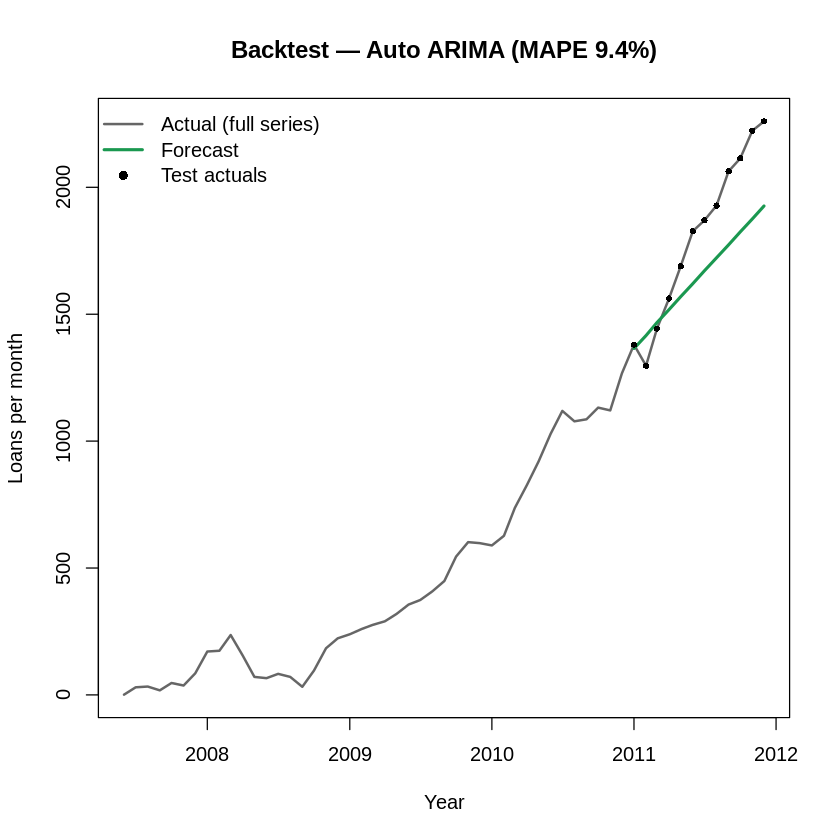

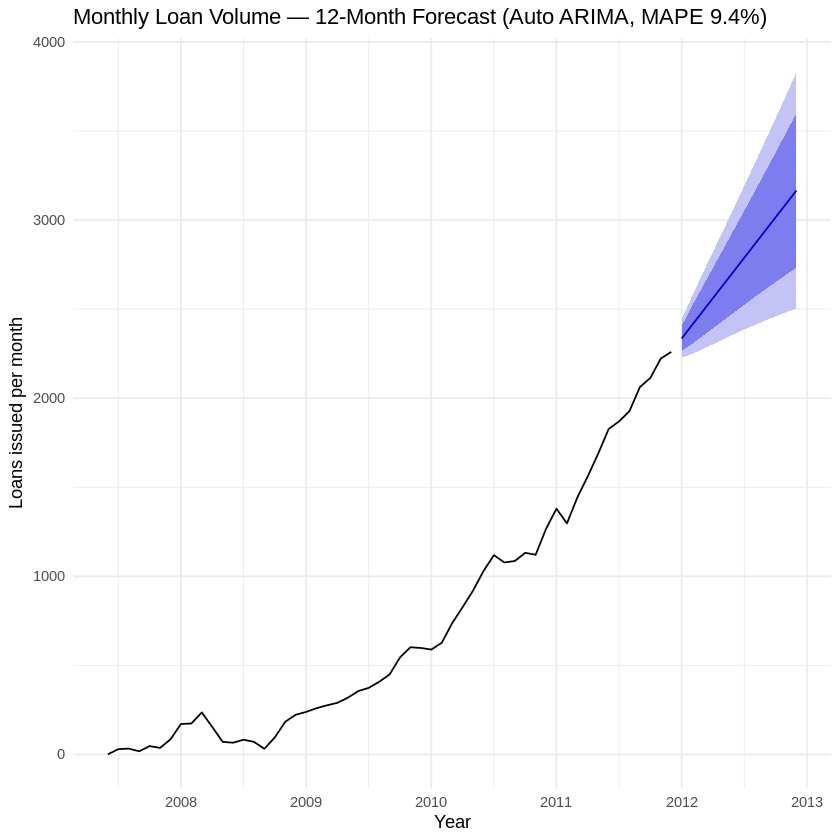

In [ ]:
backtest_fc <- forecast(candidates[[best_name]](train), h = H)

plot(monthly$month, as.numeric(y), type = "l", lwd = 2, col = "grey40",
     xlab = "Year", ylab = "Loans per month",
     main = sprintf("Backtest — %s (MAPE %.1f%%)", best_name, backtest$MAPE[1]))
lines(tail(monthly$month, H), backtest_fc$mean, col = "#1a9850", lwd = 2.5)
points(tail(monthly$month, H), as.numeric(test), col = "black", pch = 16, cex = 0.7)
invisible(legend("topleft", bty = "n",
       lwd = c(2, 2.5, NA), pch = c(NA, NA, 16),
       col = c("grey40", "#1a9850", "black"),
       legend = c("Actual (full series)", "Forecast", "Test actuals")))

# Final forecast plot (ggplot2)
p <- autoplot(final_fc) +
  ggtitle(sprintf("Monthly Loan Volume — 12-Month Forecast (%s, MAPE %.1f%%)",
                  best_name, backtest$MAPE[1])) +
  ylab("Loans issued per month") + xlab("Year") + theme_minimal()
p

SURVIVOR ANALYSIS- FALSE POSITIVES OF THE STACKING MODEL
SURVIVORS: FULLY-PAID LOANS OUR MODEL FLAGGED AS DEFAULT

In [ ]:
library(dplyr); library(ggplot2); library(tidyr)

# rebuild RAW (un-scaled) rows, identical filtering & order to the pipeline
raw <- read.csv("/content/loan_data_cleaned.csv") %>%
  filter(loan_status != "Current") %>%
  mutate(target = ifelse(loan_status == "Charged Off", 1, 0),
         .row   = row_number())

ATTACH STACKING PREDICTION TO THE RAW TEST ROWS AND RECORDER PREDICTIONS TO MATCH raw_test's ROW ORDER

In [ ]:
raw_test <- raw %>% filter(.row %in% test_ids) %>% arrange(.row)
stopifnot(nrow(raw_test) == length(p_te_stack))     # safety: must line up

ord <- order(test_ids)
raw_test$prob   <- p_te_stack[ord]
raw_test$actual <- y_te[ord]



LABEL THE THREE GROUPS: ACTUAL DEFAULT, SURVIVOR AND CORRECTLY-CLASSIFIED PAID

In [ ]:
raw_test <- raw_test %>%
  mutate(group = case_when(
    actual == 1                    ~ "Actual Default",
    actual == 0 & prob > thr_stack ~ "Survivor (false positive)",
    TRUE                           ~ "Correctly-classified Paid"))

print(table(raw_test$group))
cat(sprintf("Survivors = %.1f%% of paid loans in test\n",
    100*sum(raw_test$group=="Survivor (false positive)")/sum(raw_test$actual==0)))


           Actual Default Correctly-classified Paid Survivor (false positive) 
                     1126                      4887                      1703 
Survivors = 25.8% of paid loans in test


compare groups on RAW interpretable values

In [ ]:
feats <- intersect(c("loan_amnt","dti","delinq_2yrs","inq_last_6mths","revol_util_percent",
          "int_rate_percent","term_months","open_acc","total_acc","credit_history_months",
          "annual_inc"), names(raw_test))
group_means <- raw_test %>% group_by(group) %>%
  summarise(n=n(), across(all_of(feats), ~round(mean(.x,na.rm=TRUE),2)), .groups="drop")
print(as.data.frame(group_means))

                      group    n loan_amnt   dti delinq_2yrs inq_last_6mths
1            Actual Default 1126  11881.64 13.85        0.16           0.99
2 Correctly-classified Paid 4887  10119.58 12.74        0.13           0.71
3 Survivor (false positive) 1703  12560.95 14.81        0.20           1.20
  revol_util_percent int_rate_percent term_months open_acc total_acc
1              55.97            13.92       46.29     9.10     20.99
2              43.57            10.43       38.07     9.50     22.41
3              59.50            15.16       49.95     9.27     21.50
  credit_history_months annual_inc
1                157.13   62493.50
2                165.67   72521.20
3                162.47   57728.44


SURVIVOR V/S ACTUAL DEFAULT

In [ ]:

sig <- bind_rows(lapply(feats, function(f){
  s <- raw_test[[f]][raw_test$group=="Survivor (false positive)"]
  d <- raw_test[[f]][raw_test$group=="Actual Default"]
  data.frame(feature=f, survivor_mean=round(mean(s,na.rm=T),2),
             default_mean=round(mean(d,na.rm=T),2),
             p_value=signif(wilcox.test(s,d)$p.value,3))
})) %>% arrange(p_value)
cat("\n===== Survivor vs Default (Wilcoxon)" =====\n""); print(sig)


===== Survivor vs Default (Wilcoxon) =====
                 feature survivor_mean default_mean  p_value
1       int_rate_percent         15.16        13.92 0.00e+00
2            term_months         49.95        46.29 2.00e-15
3         inq_last_6mths          1.20         0.99 7.25e-07
4                    dti         14.81        13.85 1.21e-04
5     revol_util_percent         59.50        55.97 8.54e-04
6            delinq_2yrs          0.20         0.16 7.62e-03
7              loan_amnt      12560.95     11881.64 4.41e-02
8             annual_inc      57728.44     62493.50 1.51e-01
9              total_acc         21.50        20.99 3.01e-01
10 credit_history_months        162.47       157.13 3.17e-01
11              open_acc          9.27         9.10 6.25e-01


KEY RAW FEATURE DISTRIBUTION

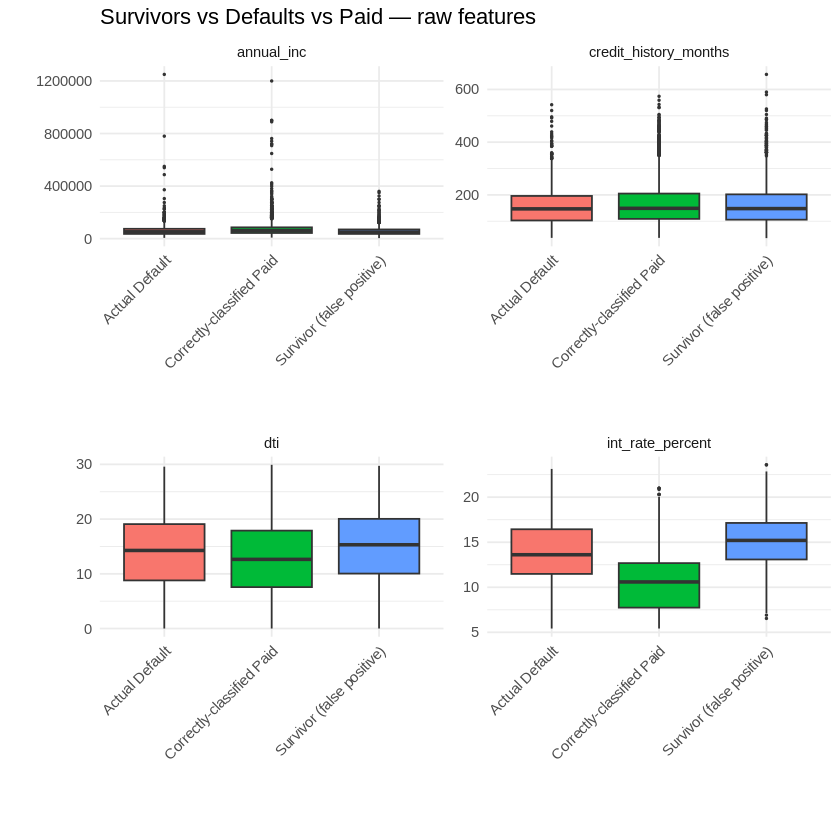

In [ ]:
key <- intersect(c("annual_inc","dti","credit_history_months","int_rate_percent","residual_income"), names(raw_test))
raw_test %>% select(all_of(key), group) %>%
  pivot_longer(-group, names_to="feature", values_to="value") %>%
  ggplot(aes(group, value, fill=group)) +
  geom_boxplot(outlier.size=0.3) + facet_wrap(~feature, scales="free") +
  theme_minimal() + theme(axis.text.x=element_text(angle=45,hjust=1), legend.position="none") +
  labs(title="Survivors vs Defaults vs Paid — raw features", x="", y="")

In [ ]:
library(dplyr)

sub_levels <- as.vector(t(outer(LETTERS[1:7], 1:5, paste0)))

raw_test <- raw_test %>%
  mutate(
    sub_grade_numeric      = match(sub_grade, sub_levels),
    inq_open_ratio         = inq_last_6mths / (open_acc + 1),
    loan_to_income         = loan_amnt / annual_inc,
    debt_service_ratio     = (installment + (dti/100 * annual_inc/12)) / (annual_inc/12),
    residual_income        = (annual_inc/12) - installment - (dti/100 * annual_inc/12),
    total_debt             = dti * annual_inc / 100,
    dti_squared            = dti^2,
    term_grade_interaction = term_months * sub_grade_numeric,
    grade_dti_risk         = sub_grade_numeric * (dti / 100),
    income_history_score   = (annual_inc / 10000) * (credit_history_months / 12),
    income_history_ratio   = annual_inc / (credit_history_months + 1),
    util_stress            = revol_util_percent * (delinq_2yrs + 1),
    high_util_flag         = as.integer(revol_util_percent > 80),
    recent_stress          = as.integer(inq_last_6mths > 2) + as.integer(delinq_2yrs > 0) +
                             as.integer(mths_since_last_delinq < 12 & !is.na(mths_since_last_delinq)) +
                             as.integer(revol_util_percent > 80),
    risk_index             = (sub_grade_numeric/35)*0.25 + (inq_open_ratio/2)*0.20 + (dti/40)*0.15 +
                             (loan_to_income)*0.15 + as.numeric(term_months == 60)*0.15 + (delinq_2yrs/5)*0.10
  )

raw_test <- raw_test %>% left_join(state_map, by = "addr_state") %>%
  mutate(state_te = ifelse(is.na(state_te), glob, state_te))

eng_feats <- c("risk_index","term_grade_interaction","grade_dti_risk","state_te",
               "residual_income","income_history_ratio","income_history_score",
               "loan_to_income","debt_service_ratio","total_debt","util_stress",
               "inq_open_ratio","dti_squared","sub_grade_numeric")
eng_feats <- intersect(eng_feats, names(raw_test))

group_means_eng <- raw_test %>% group_by(group) %>%
  summarise(n = n(), across(all_of(eng_feats), ~ round(mean(.x, na.rm=TRUE), 3)), .groups="drop")
print(as.data.frame(group_means_eng))

sig_eng <- bind_rows(lapply(eng_feats, function(f){
  s <- raw_test[[f]][raw_test$group == "Survivor (false positive)"]
  d <- raw_test[[f]][raw_test$group == "Actual Default"]
  data.frame(feature=f, survivor_mean=round(mean(s,na.rm=T),3),
             default_mean=round(mean(d,na.rm=T),3),
             p_value=signif(wilcox.test(s,d)$p.value,3))
})) %>% arrange(p_value)

print(sig_eng, row.names = FALSE)

                      group    n risk_index term_grade_interaction
1            Actual Default 1126      0.267                706.934
2 Correctly-classified Paid 4887      0.152                308.584
3 Survivor (false positive) 1703      0.316                858.638
  grade_dti_risk state_te residual_income income_history_ratio
1          2.039    0.148        4175.789              454.286
2          1.041    0.144        5008.287              495.574
3          2.491    0.150        3772.710              414.946
  income_history_score loan_to_income debt_service_ratio total_debt util_stress
1               88.786          0.220              0.213   8368.432      63.516
2              108.977          0.161              0.187   8690.734      48.749
3               84.967          0.232              0.224   8460.120      69.465
  inq_open_ratio dti_squared sub_grade_numeric
1          0.120     235.003            14.414
2          0.075     206.938             8.005
3          0.138   